# Tahap 17 — E2 amplitude-aware controls

**Analisis tambahan eksploratori**, dirancang setelah E2 awal diketahui. Tidak
mengubah preregistrasi, E1/E2 sebelumnya, manuskrip, bobot atau scientific recipe
model. Tidak ada training atau tuning model; E3 belum dilakukan. Pemeriksaan
runtime tambahan di bawah hanya memulihkan kompatibilitas numerik setelah restart.

Pertanyaan: apakah ranking attention memilih input berpengaruh melebihi kontrol
magnitude dan kontrol acak dengan amplitudo/geometri intervensi yang sebanding?
Gunakan run E2 lengkap yang dipatok di konfigurasi. Notebook berhenti jika
checkpoint, normalizer, split, donor, versi, input atau baseline tidak cocok.

Sel metode dalam notebook ini menjadi sumber penelitian untuk kontrol baru.
Pembaruan tetap melalui builder `.py`; jangan edit `.ipynb` langsung. Notebook
telah dibuat melalui builder. Buka ulang berkas dari disk, lalu gunakan kernel
Skripsi (.venv), **Restart Kernel and Run All**. Hasil ditulis ke direktori run baru.

Tidak ada hasil kontrol baru sampai notebook Anda dijalankan. Klaim faithfulness
tetap dibatasi; hasil positif, negatif, dan matching yang tidak mencukupi sama-sama
merupakan kemungkinan yang harus dilaporkan.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
import sys, json, pickle, platform, unittest
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/audit_e2.py').is_file()), None)
if ROOT is None: raise FileNotFoundError('jalankan dari root proyek/notebooks')
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from scipy.special import expit
from IPython.display import display
from audit_e0_e1 import AlignmentError, file_sha256, bootstrap_subject_table
from audit_e2 import apply_mask, keyed_seed
from e2_checkpoints import get_fold_model, FrozenPredictor, spec_digest
from newhandpd import muat_cache_bisp
from artefak import simpan_atomik
from viz import pasang_gaya, rapikan
pasang_gaya()


## 1. Desain yang dikunci sebelum kontrol baru dijalankan

Recipe induk tetap: NewHandPD spiral, checkpoint BiGRU/BiMamba-2 seed 0/1/2,
split subjek aktual, normalizer training, P=7, Fs=100 Hz, budget 5/10/20/30%,
seluruh kanal diganti bersama, T/grid/tail tetap, forward batch 1, kelas prediksi
asli, dua masker dan **library donor training yang sama persis**.

Untuk background b, energi patch j adalah jumlah `(x-b)**2` pada seluruh sampel
dan kanal patch di representasi normalized yang sudah dipakai model. RMS seluruh
rekaman setelah mengganti set S adalah `sqrt(sum(energi[S]) / (T*C))`.

- **Magnitude-ranked:** urutkan energi perubahan input dari besar ke kecil,
  tie dipecahkan secara seeded. Prefix ranking nested memakai k yang sama dengan
  attention. Lokasi/run mengikuti ranking magnitude; geometrinya dilaporkan,
  tetapi tidak dipaksakan sama dengan attention.
- **RMS-matched random:** sampel acak penempatan run dengan **multiset panjang run
  yang sama persis** dengan mask attention, pada grid linear yang sama. Ini
  menyamakan k, jumlah run dan panjang masing-masing run. Sampling gap dengan
  stars-and-bars dan permutasi run memberi kandidat uniform pada geometri itu;
  rejection sampling kemudian membatasi RMS ±5% (+ toleransi absolut 1e-8).
  Mask identik dengan attention dikecualikan; overlap lain diperbolehkan/dilaporkan.
  Kandidat dibuat tanpa label atau keluaran masked model.

Matched masks dipilih **per budget**, sehingga tidak dijamin nested antar-budget.
Recipe attention, magnitude dan baseline acak nested lama tetap dipertahankan.
Kontras per-budget dilaporkan; area kurva matched merupakan integral rerata
kontrol kondisional per-budget, bukan satu lintasan penghapusan nested.

Kontrol lama mempunyai 20 repeat: median 20, donor 4 per masing-masing 5 donor.
Kuota itu dipertahankan untuk matching. Tidak cukup kuota pada satu donor membuat
budget donor tersebut tidak tersedia; background yang berhasil tidak direweight.
Tidak ada nearest-match fallback atau pelonggaran kaliper setelah melihat output.


In [2]:
BASELINE_RUN_ID = '20261012T050124548170Z'
BASELINE = ROOT / 'results/e2' / BASELINE_RUN_ID
NOTEBOOK_PATH = ROOT / 'notebooks/17_e2_amplitude_controls.ipynb'
BUILDER_PATH = ROOT / 'scripts/build_nb_17.py'
MATCH_SEED = 1700
RMS_REL_TOL, RMS_ABS_TOL = .05, 1e-8
MAX_CANDIDATES_PER_BUDGET = 4096
CANDIDATE_BATCH = 128  # kandidat CPU; forward model tetap batch 1
N_BOOT, BOOT_SEED, CONFIDENCE = 5000, 1601, .95
MIN_SUBJECTS_FOR_CI = 10  # aturan pelaporan konservatif; bukan perhitungan power
METRICS = ('abs_delta_logit', 'signed_margin_drop', 'predicted_class_prob_drop')
# Cache GRU run terputus boleh dibaca jika metode/recipe/input sama persis.
LEGACY_MANIFEST = ROOT / 'results/e2_amplitude/20261012T080638451478Z/analysis_manifest.json'
LEGACY_CONTROL_ID = 'af1a2eff6aff8b2db99dd7b68f01ab20c5c8016a7d834aa562fae4a03ef60547'
RESUME_RUNS=(('20261012T080638451478Z',LEGACY_CONTROL_ID),
    ('20261012T090509359388Z','34803766301db0c83f578eccf53e07047aa019a7f7645fa42c9b9ed222592987'))
MAX_BACKEND_PROFILES=56
if not (0 < RMS_REL_TOL < 1 and RMS_ABS_TOL >= 0
        and MAX_CANDIDATES_PER_BUDGET >= 1 and CANDIDATE_BATCH >= 1
        and MIN_SUBJECTS_FOR_CI >= 2):
    raise ValueError('konfigurasi kontrol tidak valid')


## 2. Metode kontrol — seluruh implementasi baru dalam notebook

Sampling kandidat dibatasi agar kegagalan overlap dapat dilaporkan. Status gagal
berarti **match tidak ditemukan dalam budget pencarian yang ditetapkan**, bukan
bukti bahwa match secara matematis mustahil. Target RMS nol ditandai khusus.
Tidak ada pemilihan kandidat berdasarkan keberhasilan mengubah prediksi.


In [3]:
def mask_hash(selected):
    from hashlib import sha256
    return sha256(np.asarray(selected, dtype='<i8').tobytes()).hexdigest()


def validate_recording(recording, manifest_row, fs):
    # Rekaman.kelompok adalah teks HC/PD; properti label adalah encoding resmi proyek.
    if recording.kelompok not in {'HC','PD'}:
        raise AlignmentError(f'kelompok tidak dikenal: {recording.kelompok!r}')
    if (str(recording.subjek)!=manifest_row.subject
            or int(recording.label)!=int(manifest_row.label)
            or int(recording.tugas)!=int(manifest_row.task)
            or len(recording.kanal)!=int(manifest_row.n_samples)
            or recording.kanal.shape[1]!=6 or recording.fs!=fs):
        raise AlignmentError(f'recording cache tidak sesuai manifest: {manifest_row.record_id}; '
                             f'kelompok={recording.kelompok}, label={recording.label}, '
                             f'expected_label={int(manifest_row.label)}')


def mask_runs(selected):
    selected = np.asarray(selected, dtype=int)
    if len(selected) == 0 or not np.array_equal(selected, np.unique(selected)):
        raise AlignmentError('mask harus sorted, unik, tidak kosong')
    cuts = np.flatnonzero(np.diff(selected) > 1) + 1
    runs = np.split(selected, cuts)
    starts = np.array([r[0] for r in runs], int)
    ends = np.array([r[-1] + 1 for r in runs], int)
    return starts, ends, tuple(sorted((ends - starts).tolist()))


def patch_energy(x, background, patch):
    if x.shape != background.shape or x.ndim != 2:
        raise AlignmentError('bentuk background berubah')
    w = len(x) // patch
    delta = x[:w*patch].astype(float) - background[:w*patch].astype(float)
    return (delta.reshape(w, patch, x.shape[1]) ** 2).sum(axis=(1, 2))


def geometry_candidates(rng, w, lengths, count):
    # Permutasi multiset run + komposisi uniform gap bebas; gap internal >=1.
    lengths = np.asarray(lengths, int)
    m, k = len(lengths), int(lengths.sum())
    free = w - k - (m - 1)
    if m < 1 or (lengths < 1).any() or free < 0:
        raise AlignmentError('geometri tidak dapat ditempatkan pada grid')
    starts, ends = [], []
    for _ in range(count):
        order = rng.permutation(lengths)
        bars = np.sort(rng.choice(free + m, size=m, replace=False))
        gaps = np.diff(np.r_[-1, bars, free + m]) - 1
        s = np.r_[gaps[0], gaps[0] + np.cumsum(order[:-1] + gaps[1:-1] + 1)]
        starts.append(s); ends.append(s + order)
    return np.asarray(starts, int), np.asarray(ends, int)


def matched_candidates(energies, attention_mask, denominator, required, rng,
                       relative_tol, absolute_tol, max_candidates, batch):
    energies = np.asarray(energies, float)
    required = np.asarray(required, int)
    if (energies.ndim != 2 or len(required) != len(energies)
            or (required < 1).any() or not np.isfinite(energies).all()
            or (energies < 0).any() or denominator <= 0):
        raise AlignmentError('energi/kuota matching tidak valid')
    w = energies.shape[1]
    a_start, a_end, lengths = mask_runs(attention_mask)
    target = np.sqrt(energies[:, attention_mask].sum(axis=1) / denominator)
    prefix = np.column_stack([np.zeros(len(energies)), energies.cumsum(axis=1)])
    matches = [[] for _ in required]
    nearest_abs = np.full(len(energies), np.inf)
    nearest_rms = np.full(len(energies), np.nan)
    seen, drawn, identical = set(), 0, 0
    while drawn < max_candidates and any(len(a) < n for a, n in zip(matches, required)):
        starts, ends = geometry_candidates(rng, w, lengths, min(batch, max_candidates-drawn))
        candidate_energy = (prefix[:, ends] - prefix[:, starts]).sum(axis=2)
        rms = np.sqrt(np.maximum(candidate_energy, 0) / denominator)
        for j, (start, end) in enumerate(zip(starts, ends)):
            drawn += 1
            if np.array_equal(start, a_start) and np.array_equal(end, a_end):
                identical += 1
                continue
            signature = (tuple(start.tolist()), tuple(end.tolist()))
            if signature in seen: continue
            seen.add(signature)
            distance = abs(rms[:, j] - target)
            improve = distance < nearest_abs
            nearest_abs[improve], nearest_rms[improve] = distance[improve], rms[improve, j]
            for d in range(len(energies)):
                if (len(matches[d]) < required[d]
                        and distance[d] <= absolute_tol + relative_tol*target[d]):
                    selected = np.concatenate([np.arange(a, b) for a, b in zip(start, end)])
                    if mask_runs(selected)[2] != lengths:
                        raise AlignmentError('sampling mengubah geometri')
                    # Validasi sum langsung; prefix sums bisa kehilangan presisi pada rentang energi lebar.
                    direct_rms=float(np.sqrt(energies[d,selected].sum()/denominator))
                    if abs(direct_rms-target[d]) <= absolute_tol + relative_tol*target[d]:
                        matches[d].append(dict(selected=selected, rms=direct_rms))
            if all(len(a) == n for a, n in zip(matches, required)): break
    diagnostics = [dict(target_rms=float(target[d]), target_zero_rms=bool(target[d] <= absolute_tol),
        n_required=int(required[d]), n_matches_found=len(matches[d]),
        complete=len(matches[d]) == required[d], candidates_drawn=drawn,
        unique_geometry_candidates=len(seen), identical_attention_rejected=identical,
        nearest_alternative_rms=float(nearest_rms[d]),
        nearest_absolute_error=float(nearest_abs[d]) if np.isfinite(nearest_abs[d]) else np.nan,
        search_status='quota_reached' if len(matches[d]) == required[d] else 'insufficient_matches_within_search_budget')
        for d in range(len(energies))]
    return matches, diagnostics


def replay_donor(x, plans, training_inputs, records, train_indices, task, patch):
    background = x.copy()
    cursor, full = 0, len(x)//patch*patch
    for plan in plans:
        idx, start, stop, donor_start = (int(plan[k]) for k in
            ('donor_idx', 'target_start', 'target_stop', 'donor_start'))
        if (idx not in train_indices or int(records.iloc[idx].task) != int(task)
                or str(records.iloc[idx].subject) != str(plan['donor_subject'])
                or start != cursor or stop <= start or stop > full
                or any(v % patch for v in (start, stop, donor_start))):
            raise AlignmentError('donor bukan training same-task/grid baseline')
        data = training_inputs[idx]
        if donor_start < 0 or donor_start + stop-start > len(data)//patch*patch:
            raise AlignmentError('blok donor di luar panjang valid')
        background[start:stop] = data[donor_start:donor_start+stop-start]
        cursor = stop
    if cursor != full: raise AlignmentError('rencana donor tidak mencakup grid lengkap')
    return background


def forward_one(predictor, array):
    values = np.asarray(predictor(array[None]), float)
    if values.shape != (1,) or not np.isfinite(values).all():
        raise AlignmentError('forward harus finite dengan batch 1')
    return float(values[0])


def assert_logit(observed, expected, context):
    if not np.isclose(observed, expected, atol=1e-4, rtol=1e-4):
        raise AlignmentError(f'{context}: expected={expected:.9g}, observed={observed:.9g}, '
                             f'abs_delta={abs(observed-expected):.9g}; toleransi anchor tetap')


def evaluate_amplitude(predictor, x, alpha, original_logit, libraries, top_refs,
                       identity, fractions, patch, original_seed, random_repeats):
    # Seluruh matching selesai sebelum masked outputs baru diminta.
    w = len(x)//patch
    if (alpha.shape != (w,) or not np.isfinite(alpha).all() or (alpha < 0).any()
            or not np.isclose(alpha.sum(), 1, atol=1e-4, rtol=0)):
        raise AlignmentError('alpha baseline tidak sesuai grid/massa')
    before = forward_one(predictor, x)
    assert_logit(before, original_logit, 'anchor before '+identity['record_id'])
    tie = np.random.default_rng(keyed_seed(original_seed, identity['record_id'], 'ties')).random(w)
    attention_order = np.lexsort((tie, -alpha))
    energies = np.array([patch_energy(x, b['background'], patch) for b in libraries])
    mag_orders = []
    for b, energy in zip(libraries, energies):
        tie_mag = np.random.default_rng(keyed_seed(MATCH_SEED, identity['record_id'],
            'magnitude_tie', b['masker'], b['donor_repeat'])).random(w)
        mag_orders.append(np.lexsort((tie_mag, -energy)))
    required = [random_repeats if b['masker']=='train_median' else
                random_repeats//sum(a['masker']=='train_donor' for a in libraries) for b in libraries]
    raw, diagnostics, replay_checks, plans = [], [], [], []
    sign = 1 if original_logit >= 0 else -1
    for fraction in fractions:
        k = max(1, int(np.ceil(w*fraction)))
        attention_mask = np.sort(attention_order[:k])
        geometry = mask_runs(attention_mask)[2]
        target_hash = mask_hash(attention_mask)
        rng = np.random.default_rng(keyed_seed(MATCH_SEED, identity['model_id'],
                                             identity['record_id'], 'matched', k))
        matches, diag = matched_candidates(energies, attention_mask, x.size, required, rng,
            RMS_REL_TOL, RMS_ABS_TOL, MAX_CANDIDATES_PER_BUDGET, CANDIDATE_BATCH)
        for d, b in enumerate(libraries):
            ref = top_refs.loc[(identity['model_id'], identity['idx'], b['masker'],
                               b['donor_repeat'], float(fraction))]
            target_rms = float(np.sqrt(energies[d, attention_mask].sum()/x.size))
            if (ref.mask_sha256 != target_hash or int(ref.n_masked) != k
                    or int(ref.n_mask_runs) != len(geometry)
                    or not np.isclose(ref.input_rms_change, target_rms, atol=1e-8, rtol=1e-7)
                    or not np.isclose(ref.original_logit, original_logit, atol=1e-10, rtol=0)):
                raise AlignmentError('mask/RMS/logit attention tidak mereproduksi baseline')
            common = dict(**identity, masker=b['masker'], donor_repeat=b['donor_repeat'],
                requested_fraction=float(fraction), actual_fraction=k/w, n_masked=k,
                n_patches=w, target_mask_sha256=target_hash, target_run_lengths=json.dumps(geometry),
                target_rms=target_rms, **{f'top_{m}':float(ref[m]) for m in METRICS})
            diagnostics.append(dict(**common, **{q:v for q,v in diag[d].items() if q!='target_rms'}))
            # Verifikasi ulang titik attention pertama pada semua background yang sama.
            if fraction == fractions[0]:
                observed = forward_one(predictor, apply_mask(x, b['background'], attention_mask, patch))
                assert_logit(observed, float(ref.perturbed_logit), 'replay attention '+identity['record_id'])
                replay_checks.append(dict(**identity, masker=b['masker'], donor_repeat=b['donor_repeat'],
                    requested_fraction=float(fraction), expected=float(ref.perturbed_logit),
                    observed=observed, abs_delta=abs(observed-float(ref.perturbed_logit))))
            plans.append((common, d, 'magnitude_ranked', 0, np.sort(mag_orders[d][:k]), True))
            # Partial quotas disimpan pada diagnostics saja; tidak diinterpretasi sebagai kontrol lengkap.
            if diag[d]['complete']:
                plans.extend((common, d, 'rms_matched_random', repeat, a['selected'], True)
                             for repeat,a in enumerate(matches[d]))
    for common, d, control, repeat, selected, complete in plans:
        b = libraries[d]
        altered = apply_mask(x, b['background'], selected, patch)
        rms = float(np.sqrt(np.mean((altered.astype(float)-x)**2)))
        geometry = mask_runs(selected)[2]
        if control=='rms_matched_random' and (
                geometry != tuple(json.loads(common['target_run_lengths'])) or
                abs(rms-common['target_rms']) > RMS_ABS_TOL+RMS_REL_TOL*common['target_rms']):
            raise AlignmentError('kontrol matching melanggar kaliper/geometri')
        logit = forward_one(predictor, altered)
        values = dict(abs_delta_logit=abs(original_logit-logit),
                      signed_margin_drop=sign*(original_logit-logit),
                      predicted_class_prob_drop=float(expit(sign*original_logit)-expit(sign*logit)))
        overlap = len(np.intersect1d(selected, np.sort(attention_order[:common['n_masked']])))
        raw.append(dict(**common, control=control, repeat=repeat, original_logit=original_logit,
            perturbed_logit=logit, original_class=int(sign>0), class_flip=bool((logit>=0)!=(sign>0)),
            forward_batch_size=1, input_rms_change=rms, n_mask_runs=len(geometry),
            run_lengths=json.dumps(geometry), geometry_matches_attention=geometry==tuple(json.loads(common['target_run_lengths'])),
            mask_sha256=mask_hash(selected), selected_indices_json=json.dumps(selected.tolist()),
            rms_absolute_error=abs(rms-common['target_rms']),
            rms_relative_error=abs(rms-common['target_rms'])/common['target_rms'] if common['target_rms']>RMS_ABS_TOL else np.nan,
            attention_mask_jaccard=overlap/(2*len(selected)-overlap), **values,
            **{f'paired_{m}':common[f'top_{m}']-values[m] for m in METRICS}))
    after = forward_one(predictor, x)
    assert_logit(after, original_logit, 'anchor after '+identity['record_id'])
    raw = pd.DataFrame(raw)
    raw['unmasked_logit_before'], raw['unmasked_logit_after'] = before, after
    raw['unmasked_abs_delta_max'] = max(abs(before-original_logit), abs(after-original_logit))
    return raw, pd.DataFrame(diagnostics), pd.DataFrame(replay_checks)


## 3. Estimator berpasangan dan cakupan

Primary tetap perubahan absolut logit; signed margin dan penurunan probabilitas
kelas asli merupakan secondary. Selisih top−kontrol dibentuk pada rekaman,
checkpoint, background dan budget yang sama, sebelum agregasi.

Repeat matched dirata-ratakan per background, kemudian background diberi bobot
sama. Kurva lengkap memakai integral trapezoidal atas fraksi aktual, anchor
(0,0), dibagi fraksi maksimum, seperti E2 induk. **Tidak ada imputasi budget gagal**.

Estimasi subjek: mean seed → mean rekaman eligible per subjek → mean subjek.
Matched common-support hanya memakai rekaman yang lengkap pada **seluruh tiga
seed**; area kurva mensyaratkan seluruh empat budget dan seluruh donor lengkap.
Analisis per-budget tetap tersedia jika matching seluruh kurva tidak mencukupi.
Kontras top−magnitude dan top−acak lama juga dilaporkan pada subset matched yang
sama agar pergantian populasi analisis terlihat. Subjek tanpa rekaman eligible
tetap berada dalam pool bootstrap dengan outcome NaN, bukan dihapus diam-diam.

CI percentile 95%: 5.000 bootstrap subjek berstrata kelas, draw yang sama untuk
semua kontras. Repeat, budget, seed, dan rekaman bukan subjek independen. CI
bersyarat pada model/split/library/matching yang tersedia. Jika kurang dari 10
subjek eligible, point estimate tetap deskriptif dan CI disembunyikan; angka 10
adalah aturan pelaporan konservatif, bukan jaminan power. Cakupan kelas dilaporkan.
CI bersifat eksploratori dan tidak dikoreksi sebagai keluarga pengujian; budget
dan secondary metrics tidak dipilih berdasarkan hasil yang menguntungkan.


In [4]:
PAIR_METRICS = tuple(f'paired_{control}_{metric}'
                     for control in ('old_random', 'magnitude', 'rms') for metric in METRICS)
POINT_KEYS = ['architecture','seed','fold','model_id','idx','subject','label',
              'record_id','masker','requested_fraction','actual_fraction']


def point_contrasts(raw, diagnostics, baseline_curves, donor_repeats):
    base = baseline_curves[baseline_curves.ranking=='alpha_top'].copy()
    old = baseline_curves[baseline_curves.ranking=='random'].copy()
    base = base[POINT_KEYS+list(METRICS)].rename(columns={m:f'top_{m}' for m in METRICS})
    old = old[POINT_KEYS+list(METRICS)].rename(columns={m:f'old_random_{m}' for m in METRICS})
    output = base.merge(old,on=POINT_KEYS,validate='one_to_one')
    diag_group = diagnostics.groupby(POINT_KEYS,dropna=False)
    complete = diag_group.complete.all().rename('matched_budget_complete').reset_index()
    backgrounds = diag_group.donor_repeat.nunique().rename('n_backgrounds').reset_index()
    complete = complete.merge(backgrounds,on=POINT_KEYS,validate='one_to_one')
    expected = np.where(complete.masker=='train_median',1,donor_repeats)
    if not np.array_equal(complete.n_backgrounds.to_numpy(),expected):
        raise AlignmentError('diagnostics kehilangan background baseline')
    output = output.merge(complete,on=POINT_KEYS,validate='one_to_one')
    bg_keys=POINT_KEYS+['donor_repeat']
    if diagnostics.duplicated(bg_keys).any():raise AlignmentError('target background duplikat')
    for name,prefix in [('magnitude_ranked','magnitude'),('rms_matched_random','rms')]:
        data = raw[raw.control==name]
        if data.duplicated(bg_keys+['repeat']).any():raise AlignmentError('repeat kontrol duplikat')
        expected_rows=diagnostics[bg_keys+['n_required','complete']].copy()
        if prefix=='rms':expected_rows=expected_rows[expected_rows.complete]
        observed=data.groupby(bg_keys).size().rename('n_observed').reset_index()
        counts=expected_rows.merge(observed,on=bg_keys,how='outer',validate='one_to_one',indicator=True)
        quota=counts.n_required if prefix=='rms' else np.ones(len(counts),int)
        if (not (counts['_merge']=='both').all()
                or not np.array_equal(counts.n_observed.to_numpy(),np.asarray(quota))):
            raise AlignmentError('jumlah background/repeat kontrol tidak sesuai kuota')
        bg = data.groupby(POINT_KEYS+['donor_repeat'])[list(METRICS)].mean().reset_index()
        summary = bg.groupby(POINT_KEYS)[list(METRICS)].mean().reset_index()
        summary = summary.rename(columns={m:f'{prefix}_{m}' for m in METRICS})
        output = output.merge(summary,on=POINT_KEYS,how='left',validate='one_to_one')
    if output[[f'magnitude_{m}' for m in METRICS]].isna().any().any():
        raise AlignmentError('magnitude control tidak lengkap')
    output.loc[~output.matched_budget_complete,[f'rms_{m}' for m in METRICS]]=np.nan
    if output.loc[output.matched_budget_complete,[f'rms_{m}' for m in METRICS]].isna().any().any():
        raise AlignmentError('kuota RMS complete tetapi output kontrol hilang')
    for control in ('old_random','magnitude','rms'):
        for metric in METRICS:
            output[f'paired_{control}_{metric}']=output[f'top_{metric}']-output[f'{control}_{metric}']
    return output


def record_contrasts(points, baseline_scores, fractions):
    keys = POINT_KEYS[:-2]
    old = baseline_scores.set_index(['model_id','idx','masker'])
    rows=[]
    for key,data in points.groupby(keys,sort=True):
        data=data.sort_values('requested_fraction')
        if tuple(data.requested_fraction)!=tuple(fractions):
            raise AlignmentError('kurva kehilangan budget baseline')
        row=dict(zip(keys,key))
        complete=bool(data.matched_budget_complete.all())
        row['matched_curve_complete']=complete
        grid=np.r_[0.,data.actual_fraction.to_numpy()]
        for metric in METRICS:
            for control in ('top','old_random','magnitude','rms'):
                values=data[f'{control}_{metric}'].to_numpy()
                row[f'aopc_{control}_{metric}']=(float(np.trapezoid(np.r_[0.,values],grid)/grid[-1])
                                               if np.isfinite(values).all() else np.nan)
            for control in ('old_random','magnitude','rms'):
                row[f'paired_{control}_{metric}']=row[f'aopc_top_{metric}']-row[f'aopc_{control}_{metric}']
            previous=old.loc[(row['model_id'],row['idx'],row['masker'])]
            if (not np.isclose(row[f'aopc_top_{metric}'],previous[f'alpha_top_{metric}'],atol=1e-8,rtol=1e-8)
                    or not np.isclose(row[f'aopc_old_random_{metric}'],previous[f'random_{metric}'],atol=1e-8,rtol=1e-8)):
                raise AlignmentError('integral baseline tidak cocok dengan E2 lama')
        rows.append(row)
    return pd.DataFrame(rows)


def subject_contrasts(wide, seeds, complete_column, extra_keys=()):
    # Berpasangan dahulu. Seed tidak di-drop/reweight jika matching sebagian gagal.
    record_keys=['architecture','masker','subject','label','idx',*extra_keys]
    rows=[]
    for key,data in wide.groupby(record_keys,dropna=False,sort=True):
        if len(data)!=len(seeds) or set(data.seed)!=set(seeds):
            raise AlignmentError('rekaman harus mencakup setiap seed tepat sekali')
        common=dict(zip(record_keys,key))
        for scope in ('full_baseline','matched_common_support'):
            eligible=scope=='full_baseline' or bool(data[complete_column].all())
            row=dict(**common,scope=scope,record_eligible=int(eligible))
            for metric in PAIR_METRICS:
                values=data[metric].to_numpy(float)
                allowed=eligible and np.isfinite(values).all()
                if scope=='full_baseline' and metric.startswith('paired_rms_'):allowed=False
                row[metric]=float(values.mean()) if allowed else np.nan
            rows.append(row)
    per_record=pd.DataFrame(rows)
    subject_keys=['architecture','masker','scope','subject','label',*extra_keys]
    subjects=per_record.groupby(subject_keys,dropna=False)[list(PAIR_METRICS)].mean().reset_index()
    coverage=per_record.groupby(subject_keys,dropna=False).agg(
        n_records_total=('idx','size'),n_records_eligible=('record_eligible','sum')).reset_index()
    coverage['fraction_records_eligible']=coverage.n_records_eligible/coverage.n_records_total
    return per_record,subjects.merge(coverage,on=subject_keys,validate='one_to_one')


def paired_ci(subjects, extra_keys=()):
    tables=[]
    for scope in ('full_baseline','matched_common_support'):
        metrics=PAIR_METRICS if scope=='matched_common_support' else tuple(
            m for m in PAIR_METRICS if not m.startswith('paired_rms_'))
        data=subjects[subjects.scope==scope]
        table=bootstrap_subject_table(data,metrics+('fraction_records_eligible',),
            group_columns=('architecture','masker','scope',*extra_keys),
            n_boot=N_BOOT,random_seed=BOOT_SEED,confidence=CONFIDENCE)
        small=table.n_subjects_valid<MIN_SUBJECTS_FOR_CI
        table['interpretation_status']=np.where(small,'descriptive_only_low_coverage','conditional_exploratory')
        table.loc[small,['ci_low','ci_high']]=np.nan
        table['confidence']=CONFIDENCE
        table['status']='exploratory_after_E2_baseline'
        table['inference']='CI subjek paired, bersyarat pada checkpoint/split/seed/library dan matching; bukan validasi fisiologis'
        tables.append(table)
    return pd.concat(tables,ignore_index=True)


def notebook_source_digest(path):
    from hashlib import sha256
    nb=json.loads(Path(path).read_text())
    source=[dict(type=c['cell_type'],source=''.join(c.get('source',[]))) for c in nb['cells']]
    return sha256(json.dumps(source,sort_keys=True,ensure_ascii=False).encode()).hexdigest()


## 4. Pemeriksaan sintetis CPU

Sel berikut hanya dijalankan oleh Anda. Menguji geometri, RMS, identitas masker,
kegagalan matching tanpa fallback, pemisahan donor, dan agregasi subjek/seed.
Tidak membaca data penelitian atau menjalankan model. Agen belum menjalankannya.


In [5]:
class AmplitudeChecks(unittest.TestCase):
    def test_recording_group_strings_use_project_label_property(self):
        from preprocessing import Rekaman
        for group,label in [('HC',0),('PD',1)]:
            recording=Rekaman(subjek='s',kelompok=group,tugas=0,segmen=0,fs=100.,
                              kanal=np.zeros((4,6),np.float32))
            manifest_row=pd.Series(dict(subject='s',label=label,task=0,n_samples=4,record_id='test'))
            validate_recording(recording,manifest_row,100.)
            wrong=manifest_row.copy();wrong['label']=1-label
            with self.assertRaises(AlignmentError):validate_recording(recording,wrong,100.)
        invalid=Rekaman(subjek='s',kelompok='unknown',tugas=0,segmen=0,fs=100.,
                        kanal=np.zeros((4,6),np.float32))
        with self.assertRaisesRegex(AlignmentError,'kelompok tidak dikenal'):
            validate_recording(invalid,manifest_row,100.)

    def test_geometry_and_budget(self):
        rng=np.random.default_rng(17)
        starts,ends=geometry_candidates(rng,15,(1,2,2),20)
        for s,e in zip(starts,ends):
            mask=np.concatenate([np.arange(a,b) for a,b in zip(s,e)])
            self.assertEqual(len(mask),5)
            self.assertEqual(mask_runs(mask)[2],(1,2,2))
            self.assertTrue((mask>=0).all() and (mask<15).all())

    def test_energy_rms_tail_and_magnitude(self):
        x=np.arange(22,dtype=np.float32).reshape(11,2)
        background=np.zeros_like(x);selected=np.array([0,2])
        e=patch_energy(x,background,3)
        changed=apply_mask(x,background,selected,3)
        self.assertAlmostEqual(np.sqrt(e[selected].sum()/x.size),
                               np.sqrt(np.mean((changed.astype(float)-x)**2)))
        np.testing.assert_array_equal(changed[9:],x[9:])
        np.testing.assert_array_equal(np.argsort(-e),[2,1,0])
        donor=x.copy();donor[:3]-=100
        self.assertEqual(int(np.argmax(patch_energy(x,donor,3))),0)

    def test_matching_requires_alternatives_and_caliper(self):
        matches,diag=matched_candidates(np.ones((2,9)),np.array([1,2]),9,[3,2],
            np.random.default_rng(3),.05,1e-8,128,16)
        self.assertTrue(all(d['complete'] for d in diag))
        for library in matches:
            self.assertEqual(len({mask_hash(a['selected']) for a in library}),len(library))
            for a in library:
                self.assertNotEqual(mask_hash(a['selected']),mask_hash([1,2]))
                self.assertEqual(mask_runs(a['selected'])[2],(2,))
                self.assertAlmostEqual(a['rms'],np.sqrt(2/9))

    def test_no_nearest_fallback(self):
        energy=np.array([[100.,0.,0.,0.,0.,0.,0.,0.]])
        matches,diag=matched_candidates(energy,np.array([0]),8,[2],
            np.random.default_rng(4),.05,1e-8,64,8)
        self.assertEqual(matches,[[]])
        self.assertFalse(diag[0]['complete'])
        self.assertEqual(diag[0]['search_status'],'insufficient_matches_within_search_budget')

    def test_donor_cannot_use_test_record(self):
        x=np.ones((4,1),np.float32)
        rec=pd.DataFrame([dict(subject='train',task=0),dict(subject='test',task=0)])
        plan=[dict(donor_idx=1,target_start=0,target_stop=4,donor_start=0,donor_subject='test')]
        with self.assertRaises(AlignmentError):replay_donor(x,plan,{0:x},rec,{0},0,1)

    def test_missing_background_cannot_be_silently_reweighted(self):
        common=dict(architecture='gru',seed=0,fold=0,model_id='m',idx=0,
            subject='s',label=0,record_id='r',masker='train_donor',
            requested_fraction=.25,actual_fraction=.25)
        baseline=pd.DataFrame([dict(**common,ranking=rank,**{m:value for m in METRICS})
                               for rank,value in [('alpha_top',2.),('random',1.)]])
        diag=pd.DataFrame([dict(**common,donor_repeat=d,n_required=1,complete=True) for d in (0,1)])
        raw=pd.DataFrame([dict(**common,donor_repeat=0,control='magnitude_ranked',repeat=0,
                              **{m:1. for m in METRICS})])
        with self.assertRaisesRegex(AlignmentError,'background/repeat'):
            point_contrasts(raw,diag,baseline,donor_repeats=2)

    def test_subject_weighting_and_all_seed_common_support(self):
        rows=[]
        for subject,idx,value,complete in [('s1',0,2.,True),('s1',1,10.,False),('s2',2,1.,True)]:
            for seed in (0,1,2):
                row=dict(architecture='gru',masker='train_median',subject=subject,label=0,
                         idx=idx,seed=seed,matched_curve_complete=complete or seed!=2)
                row.update({m:value for m in PAIR_METRICS});rows.append(row)
        _,table=subject_contrasts(pd.DataFrame(rows),(0,1,2),'matched_curve_complete')
        full=table[table.scope=='full_baseline'].set_index('subject')
        common=table[table.scope=='matched_common_support'].set_index('subject')
        self.assertEqual(full.loc['s1','paired_magnitude_abs_delta_logit'],6.)
        self.assertEqual(common.loc['s1','paired_magnitude_abs_delta_logit'],2.)
        self.assertEqual(common.loc['s1','n_records_eligible'],1)
        self.assertEqual(full.loc['s2','paired_magnitude_abs_delta_logit'],1.)

suite=unittest.defaultTestLoader.loadTestsFromTestCase(AmplitudeChecks)
preflight=unittest.TextTestRunner(verbosity=2).run(suite)
if not preflight.wasSuccessful():raise RuntimeError('pemeriksaan sintetis gagal; model belum dijalankan')


test_donor_cannot_use_test_record (__main__.AmplitudeChecks.test_donor_cannot_use_test_record) ... ok
test_energy_rms_tail_and_magnitude (__main__.AmplitudeChecks.test_energy_rms_tail_and_magnitude) ... ok
test_geometry_and_budget (__main__.AmplitudeChecks.test_geometry_and_budget) ... ok
test_matching_requires_alternatives_and_caliper (__main__.AmplitudeChecks.test_matching_requires_alternatives_and_caliper) ... ok
test_missing_background_cannot_be_silently_reweighted (__main__.AmplitudeChecks.test_missing_background_cannot_be_silently_reweighted) ... ok
test_no_nearest_fallback (__main__.AmplitudeChecks.test_no_nearest_fallback) ... ok
test_recording_group_strings_use_project_label_property (__main__.AmplitudeChecks.test_recording_group_strings_use_project_label_property) ... ok
test_subject_weighting_and_all_seed_common_support (__main__.AmplitudeChecks.test_subject_weighting_and_all_seed_common_support) ... ok

----------------------------------------------------------------------


### Pemeriksaan alpha numerik dan mask intervensi

Nilai alpha diuji dengan toleransi lama **atol=1e-6, rtol=1e-4**, tanpa
pelonggaran. Hasil numerik, ukuran selisih, massa, hash mask pada empat budget,
dan konteks backend dicatat terpisah. Ranking E2 menggunakan alpha baseline;
alpha baru tidak menggantikan peta lama.

Keabsahan kontrol bergantung pada intervensi yang sama. **Set patch attention
harus identik pada setiap budget**, dengan tie seed yang sama. Jika nilai alpha
berbeda di luar toleransi tetapi semua mask identik, seluruh titik attention pada
keenam background harus mereproduksi logit baseline dengan toleransi logit lama.
Kasus ini ditandai `exact_masks_all_point_replay`, bukan "alpha identik". Jika
mask atau respons replay berbeda, notebook berhenti dan menyimpan diagnostik;
tidak ada fallback untuk mengubah mask, model atau toleransi.

Probe pertama memakai rekaman pertama BiMamba-2 sebelum loop kontrol yang mahal.
Cache GRU lama tetap boleh dipakai setelah pemeriksaan input/metode/recipe dan
revalidasi alpha/logit saat ini. Validasi tambahan tidak mengubah fungsi sampling,
intervensi, estimator, atau bobot model dari run sebelumnya.


In [6]:
PROTOCOL_FUNCTIONS=('mask_hash','validate_recording','mask_runs','patch_energy',
    'geometry_candidates','matched_candidates','replay_donor','forward_one','assert_logit',
    'evaluate_amplitude','point_contrasts','record_contrasts','subject_contrasts','paired_ci')


def protocol_signature(path):
    import ast
    from hashlib import sha256
    nb=json.loads(Path(path).read_text())
    source='\n'.join(''.join(c.get('source',[])) for c in nb['cells'] if c['cell_type']=='code')
    tree=ast.parse(source)
    nodes={n.name:ast.dump(n,include_attributes=False) for n in tree.body
           if isinstance(n,ast.FunctionDef) and n.name in PROTOCOL_FUNCTIONS}
    if set(nodes)!=set(PROTOCOL_FUNCTIONS):raise AlignmentError('metode kontrol tidak lengkap')
    return sha256(json.dumps(nodes,sort_keys=True).encode()).hexdigest()


def alpha_report(saved, fresh, record_id, original_seed, fractions):
    saved,fresh=np.asarray(saved,float),np.asarray(fresh,float)
    result=dict(alpha_values_allclose=False,alpha_shapes_match=saved.shape==fresh.shape,
        alpha_masks_identical=False,alpha_max_abs_diff=np.nan,alpha_l1_diff=np.nan,
        alpha_outside_tolerance=np.nan,saved_mass=float(saved.sum()),fresh_mass=float(fresh.sum()))
    if (saved.ndim!=1 or fresh.shape!=saved.shape or not np.isfinite(saved).all()
            or not np.isfinite(fresh).all() or (saved<0).any() or (fresh<0).any()
            or not np.isclose(saved.sum(),1,atol=1e-4,rtol=0)
            or not np.isclose(fresh.sum(),1,atol=1e-4,rtol=0)):
        result['reason']='shape_or_mass_or_finiteness';return result
    difference=abs(saved-fresh)
    result.update(alpha_values_allclose=bool(np.allclose(fresh,saved,atol=1e-6,rtol=1e-4)),
        alpha_max_abs_diff=float(difference.max()),alpha_l1_diff=float(difference.sum()),
        alpha_outside_tolerance=int((difference>1e-6+1e-4*abs(saved)).sum()))
    tie=np.random.default_rng(keyed_seed(original_seed,record_id,'ties')).random(len(saved))
    old_order,new_order=np.lexsort((tie,-saved)),np.lexsort((tie,-fresh))
    masks=[]
    for fraction in fractions:
        k=max(1,int(np.ceil(len(saved)*fraction)))
        a,b=np.sort(old_order[:k]),np.sort(new_order[:k])
        masks.append(dict(fraction=float(fraction),k=k,saved_hash=mask_hash(a),fresh_hash=mask_hash(b),
            n_patch_symmetric_difference=len(np.setxor1d(a,b))))
    result['alpha_masks_identical']=all(m['saved_hash']==m['fresh_hash'] for m in masks)
    result['masks']=masks
    result['reason']='strict_values' if result['alpha_values_allclose'] else 'numerical_values_differ'
    return result


def make_libraries(x, donor_library, training_inputs, train, rec):
    libraries=[dict(masker='train_median',donor_repeat=0,background=np.zeros_like(x))]
    if len(donor_library)!=DONOR_REPEATS or {a['donor_repeat'] for a in donor_library}!=set(range(DONOR_REPEATS)):
        raise AlignmentError('jumlah donor library berubah')
    for donor in sorted(donor_library,key=lambda a:a['donor_repeat']):
        background=replay_donor(x,donor['plans'],training_inputs,records,set(train),rec.task,PATCH)
        libraries.append(dict(masker='train_donor',donor_repeat=int(donor['donor_repeat']),background=background))
    return libraries


def verify_alpha_and_replay(predictor,x,p,fresh,observed,libraries,identity,phase):
    saved=np.asarray(p['alpha'],float)
    report=alpha_report(saved,fresh,identity['record_id'],int(recipe['intervention_seed']),FRACTIONS)
    row=dict(**identity,phase=phase,observed_logit=observed,saved_logit=float(p['logit']),
        **{k:v for k,v in report.items() if k!='masks'},
        mask_checks_json=json.dumps(report.get('masks',[])),verification='pending')
    diagnostic_rows.append(row)
    def persist():
        pd.DataFrame(diagnostic_rows).to_csv(OUT/'alpha_alignment_diagnostics.csv',index=False)
    persist()
    if not report['alpha_values_allclose'] or not report['alpha_masks_identical']:
        directory=OUT/'alpha_details';directory.mkdir(exist_ok=True)
        np.savez_compressed(directory/f"{identity['model_id']}_{identity['idx']}_{phase}.npz",
            saved_alpha=saved,fresh_alpha=np.asarray(fresh),normalized_input=x,
            saved_logit=float(p['logit']),observed_logit=observed)
    if not report['alpha_masks_identical']:
        row['verification']='failed_mask_or_map_structure';persist()
        manifest['completion_status']='failed_alpha_alignment'
        (OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
        raise AlignmentError(f"alpha tidak mereproduksi mask baseline: {identity}; "
            f"max_abs_diff={report['alpha_max_abs_diff']}, outside={report['alpha_outside_tolerance']}; "
            f"lihat {OUT/'alpha_alignment_diagnostics.csv'}")
    # Bahkan jika alpha numerik cocok, cache lama divalidasi tanpa mengulang controls.
    full_replay=(phase in {'legacy_cache','early_probe'} or identity['architecture']=='mamba2'
                 or not report['alpha_values_allclose'])
    maximum=0.
    if full_replay:
        tie=np.random.default_rng(keyed_seed(int(recipe['intervention_seed']),identity['record_id'],'ties')).random(len(saved))
        order=np.lexsort((tie,-saved))
        for fraction in FRACTIONS:
            selected=np.sort(order[:max(1,int(np.ceil(len(saved)*fraction)))])
            for b in libraries:
                ref=top_refs.loc[(identity['model_id'],identity['idx'],b['masker'],b['donor_repeat'],float(fraction))]
                value=forward_one(predictor,apply_mask(x,b['background'],selected,PATCH))
                maximum=max(maximum,abs(value-float(ref.perturbed_logit)))
                try:
                    if ref.mask_sha256!=mask_hash(selected) or int(ref.n_masked)!=len(selected):
                        raise AlignmentError('mask referensi replay berbeda: '+identity['record_id'])
                    assert_logit(value,float(ref.perturbed_logit),'all-point replay '+identity['record_id'])
                except AlignmentError:
                    row.update(verification='failed_top_logit_replay',top_replay_max_abs_diff=maximum)
                    persist()
                    manifest['completion_status']='failed_top_logit_replay'
                    (OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
                    raise
        after=forward_one(predictor,x)
        assert_logit(after,float(p['logit']),'anchor after alignment replay '+identity['record_id'])
        row['unmasked_logit_after_replay']=after
    row.update(verification='strict_values' if report['alpha_values_allclose'] else 'exact_masks_all_point_replay',
        top_replay_all_points=full_replay,top_replay_max_abs_diff=maximum if full_replay else np.nan)
    persist()
    return row


class AlphaReplayChecks(unittest.TestCase):
    def test_value_difference_does_not_imply_mask_difference(self):
        report=alpha_report(np.array([.4,.3,.2,.1]),np.array([.41,.29,.2,.1]),'toy',1600,(.25,.5,.75))
        self.assertFalse(report['alpha_values_allclose'])
        self.assertTrue(report['alpha_masks_identical'])
    def test_changed_masks_fail_operational_parity(self):
        report=alpha_report(np.array([.4,.3,.2,.1]),np.array([.1,.2,.3,.4]),'toy',1600,(.25,.5))
        self.assertFalse(report['alpha_masks_identical'])

alpha_preflight=unittest.TextTestRunner(verbosity=2).run(
    unittest.defaultTestLoader.loadTestsFromTestCase(AlphaReplayChecks))
if not alpha_preflight.wasSuccessful():raise RuntimeError('pemeriksaan alpha replay gagal')


test_changed_masks_fail_operational_parity (__main__.AlphaReplayChecks.test_changed_masks_fail_operational_parity) ... ok
test_value_difference_does_not_imply_mask_difference (__main__.AlphaReplayChecks.test_value_difference_does_not_imply_mask_difference) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.004s

OK


## 5. Verifikasi artefak induk, checkpoint dan scientific recipe

Tidak merekonstruksi split atau memasang ulang normalizer. Donor direplay dari
rencana E2 lama dan diverifikasi sebagai training same-task. Match/magnitude
hanya memakai input, alpha, background dan seed algoritme; label hanya dipakai
untuk stratifikasi bootstrap evaluasi. Tidak memakai output masked model untuk
mencari atau menerima kandidat. Tidak ada parameter baru yang dituning pada label.

Metadata/sumber/data/checkpoint/cache induk harus cocok sebelum inferensi.
Baseline top, random, dan E1 tetap dibaca sebagai artefak lama, tidak ditulis ulang.
Cache kontrol baru terpisah dan bisa dilanjutkan pada fold yang telah selesai.


In [7]:
baseline_manifest=json.loads((BASELINE/'analysis_manifest.json').read_text())
recipe=baseline_manifest['evaluation_spec']
if (baseline_manifest['completion_status']!='complete' or recipe.get('evaluation_protocol_version')!=2
        or recipe['cohort']!='newhandpd' or recipe['forward_batch_size']!=1):
    raise AlignmentError('baseline harus E2 lengkap, NewHandPD, protokol batch 1')
ARMS, SEEDS=tuple(recipe['arms']),tuple(recipe['seeds'])
FRACTIONS=tuple(recipe['fractions'])
PATCH,FS=int(recipe['patch']),float(recipe['fs'])
DONOR_REPEATS,RANDOM_REPEATS=int(recipe['donor_repeats']),int(recipe['random_repeats'])
if (ARMS!=('gru','mamba2') or SEEDS!=(0,1,2) or FRACTIONS!=(.05,.10,.20,.30)
        or PATCH!=7 or FS!=100. or DONOR_REPEATS!=5 or RANDOM_REPEATS!=20):
    raise AlignmentError('recipe baseline berbeda dari desain kontrol yang disiapkan')
if recipe['unmasked_check']!={'phases':['before','after'],'atol':1e-4,'rtol':1e-4}:
    raise AlignmentError('protokol anchor baseline berbeda')
old_inventory=pd.read_csv(BASELINE/'input_inventory.csv')
for entry in old_inventory.itertuples():
    if not entry.unchanged or file_sha256(ROOT/entry.path)!=entry.sha256_after:
        raise AlignmentError('input/sumber baseline berubah: '+entry.path)
cache_entry=next(r for r in old_inventory.itertuples() if r.path.startswith('data/cache/'))
CACHE=ROOT/cache_entry.path
if file_sha256(CACHE)!=recipe['cache_sha256']:raise AlignmentError('cache dataset berubah')
VERSIONS={p:version(p) for p in ('numpy','pandas','scipy','scikit-learn','torch')}
for package in ('mamba-ssm','causal-conv1d','triton','einops'):
    try:VERSIONS[package]=version(package)
    except PackageNotFoundError:VERSIONS[package]='metadata_version_unavailable'
VERSIONS['cuda_runtime']=str(torch.version.cuda)
if VERSIONS!=baseline_manifest['versions']:
    raise AlignmentError('versi berbeda dari baseline; hentikan dan telaah kompatibilitas tanpa training ulang')
records=pd.read_csv(BASELINE/'record_manifest.csv')
models=pd.read_csv(BASELINE/'model_inventory.csv').sort_values(['architecture','seed','fold'])
if (records.idx.duplicated().any() or not np.array_equal(records.idx.to_numpy(),np.arange(len(records)))
        or models.model_id.duplicated().any() or len(models)!=30
        or set(zip(models.architecture,models.seed,models.fold))!={(a,s,f) for a in ARMS for s in SEEDS for f in range(5)}):
    raise AlignmentError('identitas rekaman/model tidak lengkap')
specs={}
tracked={CACHE,BUILDER_PATH,BASELINE/'analysis_manifest.json',BASELINE/'input_inventory.csv',
         BASELINE/'record_manifest.csv',BASELINE/'model_inventory.csv',BASELINE/'joint_oof_maps.pkl',
         BASELINE/'e2_curves_raw.csv',BASELINE/'e2_curve_mean.csv',BASELINE/'e2_record_scores.csv',BASELINE/'e2_ci.csv',
         BASELINE/'e1_pairs_new.csv',BASELINE/'e1_ci_new.csv',BASELINE/'joint_e1_e2_ci.csv'}
tracked.update(ROOT/p for p in old_inventory.path)
tracked.update(ROOT/p for p in ('src/artefak.py','src/viz.py'))
for row in models.itertuples():
    cp=ROOT/row.checkpoint;meta_path=cp.parent/'metadata.json'
    if not cp.is_file() or not meta_path.is_file():
        raise FileNotFoundError('checkpoint/metadata hilang; notebook ini tidak melakukan training: '+row.model_id)
    meta=json.loads(meta_path.read_text());spec=meta['spec']
    if (spec_digest(spec)!=row.model_id or meta['checkpoint_sha256']!=row.checkpoint_sha256
            or file_sha256(cp)!=row.checkpoint_sha256 or spec['versions']!=VERSIONS
            or spec['cache_sha256']!=recipe['cache_sha256']
            or spec['model_config']!=recipe['model_config'] or spec['training_config']!=recipe['training_config']
            or (spec['architecture'],spec['seed'],spec['fold'])!=(row.architecture,row.seed,row.fold)):
        raise AlignmentError('spec/checkpoint baseline tidak cocok: '+row.model_id)
    for path,checksum in spec['sources'].items():
        if file_sha256(ROOT/path)!=checksum:raise AlignmentError('sumber training berubah: '+path)
    train,test=spec['split']['train_indices'],spec['split']['test_indices']
    if (set(train)&set(test) or set(train)|set(test)!=set(records.idx)
            or set(records.subject.iloc[train])&set(records.subject.iloc[test])
            or records.record_id.iloc[train].tolist()!=spec['split']['train_record_ids']
            or records.record_id.iloc[test].tolist()!=spec['split']['test_record_ids']
            or not (records.fold_actual.iloc[test]==row.fold).all()):
        raise AlignmentError('split/subject/record ID checkpoint tidak cocok')
    specs[row.model_id]=spec
    old_cache=ROOT/row.evaluation_cache
    side_path=old_cache.parent/'fold_manifest.json'
    side=json.loads(side_path.read_text())
    if (side['model_id']!=row.model_id or side['evaluation_id']!=baseline_manifest['evaluation_id']
            or side['fold_cache_sha256']!=file_sha256(old_cache)):
        raise AlignmentError('cache fold induk tidak cocok')
    tracked.update((cp,meta_path,old_cache,side_path))

old_runs=pickle.loads((BASELINE/'joint_oof_maps.pkl').read_bytes())
maps={}
for run in old_runs:
    for p in run['peta']:
        key=(p['model_id'],int(p['idx']))
        if key in maps:raise AlignmentError('peta baseline duplikat')
        rec=records.iloc[p['idx']];spec=specs[p['model_id']]
        if (str(p['subjek'])!=rec.subject or p['label']!=rec.label or p['fold']!=rec.fold_actual
                or p['seed']!=spec['seed'] or p['arsitektur']!=spec['architecture']
                or p['tugas']!=rec.task or p['fs']!=FS or p['patch']!=PATCH
                or np.asarray(p['alpha']).shape!=(int(rec.n_patches),)):
            raise AlignmentError('peta tidak cocok dengan subjek/fold/grid/checkpoint')
        maps[key]=p
if len(maps)!=len(records)*len(ARMS)*len(SEEDS):raise AlignmentError('peta baseline tidak lengkap')
del old_runs
top_columns=['ranking','model_id','idx','masker','donor_repeat','requested_fraction',
    'mask_sha256','n_masked','n_mask_runs','input_rms_change','original_logit','perturbed_logit',*METRICS]
chunks=[]
for chunk in pd.read_csv(BASELINE/'e2_curves_raw.csv',usecols=top_columns,
                         chunksize=25000,float_precision='round_trip'):
    chunks.append(chunk[chunk.ranking=='alpha_top'])
top_refs=pd.concat(chunks,ignore_index=True).set_index(
    ['model_id','idx','masker','donor_repeat','requested_fraction'])
if not top_refs.index.is_unique or len(top_refs)!=len(maps)*(1+DONOR_REPEATS)*len(FRACTIONS):
    raise AlignmentError('attention reference tidak lengkap/unik')
del chunks
baseline_curves=pd.read_csv(BASELINE/'e2_curve_mean.csv',float_precision='round_trip')
baseline_curves['record_id']=baseline_curves.idx.map(records.set_index('idx').record_id)
baseline_scores=pd.read_csv(BASELINE/'e2_record_scores.csv',float_precision='round_trip')
recordings=muat_cache_bisp(CACHE)
if len(recordings)!=len(records):raise AlignmentError('jumlah rekaman cache berbeda')
for idx,r in enumerate(recordings):
    rec=records.iloc[idx]
    validate_recording(r,rec,FS)
if not torch.cuda.is_available():raise RuntimeError('lingkungan CUDA proyek diperlukan; tidak ada training fallback')
DEVICE='cuda'
inventory=pd.DataFrame([dict(path=str(p.relative_to(ROOT)),sha256_before=file_sha256(p))
                        for p in sorted(tracked)])
SOURCE_DIGEST=notebook_source_digest(NOTEBOOK_PATH)
CONTROL_SPEC=dict(format_version=1,baseline_run_id=BASELINE_RUN_ID,
    baseline_evaluation_id=baseline_manifest['evaluation_id'],recipe=recipe,versions=VERSIONS,
    baseline_hashes=dict(zip(inventory.path,inventory.sha256_before)),notebook_source_sha256=SOURCE_DIGEST,
    matching=dict(relative_tolerance=RMS_REL_TOL,absolute_tolerance=RMS_ABS_TOL,
        max_candidates_per_budget=MAX_CANDIDATES_PER_BUDGET,candidate_batch=CANDIDATE_BATCH,
        seed=MATCH_SEED,geometry='exact multiset of linear contiguous run lengths',
        identity_excluded=True,overlap_allowed=True,nested=False,quota=RANDOM_REPEATS,
        donor_quota_per_background=RANDOM_REPEATS//DONOR_REPEATS,no_fallback=True),
    magnitude='descending patch sum squared change in normalized model input, nested prefixes per background',
    inference=dict(n_boot=N_BOOT,seed=BOOT_SEED,confidence=CONFIDENCE,
                   minimum_subjects_for_ci=MIN_SUBJECTS_FOR_CI,all_seeds_required=True),
    status='exploratory_after_E2_baseline',training_performed=False,old_preregistration_changed=False,
    alpha_validation=dict(atol=1e-6,rtol=1e-4,exact_masks_required=True,
        all_point_logit_replay_if_values_differ=True,all_point_replay_for_probe_and_legacy_cache=True,
        baseline_alpha_replaced=False),
    protocol_method_signature=protocol_signature(NOTEBOOK_PATH))
CONTROL_ID=spec_digest(CONTROL_SPEC)
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT,FIG=ROOT/'results/e2_amplitude'/RUN_ID,ROOT/'figures/e2_amplitude'/RUN_ID
OUT.mkdir(parents=True,exist_ok=False);FIG.mkdir(parents=True,exist_ok=False)
manifest=dict(run_id=RUN_ID,control_id=CONTROL_ID,control_spec=CONTROL_SPEC,
    completion_status='started',training_performed=False,old_preregistration_changed=False,
    analysis_design_date='2026-10-12',analysis_status='exploratory',
    technical_revision='alpha numerical result retained; exact masks and full baseline replay required '
                       'for values outside tolerance; scientific control methods unchanged',
    python=platform.python_version(),device=torch.cuda.get_device_name(),
    scientific_source=str(NOTEBOOK_PATH.relative_to(ROOT)),notebook_source_sha256=SOURCE_DIGEST)
manifest['backend_context']=dict(default_dtype=str(torch.get_default_dtype()),
    float32_matmul_precision=torch.get_float32_matmul_precision(),
    cuda_matmul_allow_tf32=bool(torch.backends.cuda.matmul.allow_tf32),
    cudnn_allow_tf32=bool(torch.backends.cudnn.allow_tf32),
    cudnn_benchmark=bool(torch.backends.cudnn.benchmark),
    deterministic_algorithms=torch.are_deterministic_algorithms_enabled())
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
inventory.to_csv(OUT/'input_inventory.csv',index=False)
print('Checkpoint terverifikasi:',len(models),'; training: dinonaktifkan')
print('Baseline:',BASELINE,'\nOutput baru:',OUT)
display(pd.DataFrame([dict(arms=ARMS,seeds=SEEDS,budgets=FRACTIONS,
    rms_caliper=RMS_REL_TOL,max_candidates=MAX_CANDIDATES_PER_BUDGET,forward_batch=1)]))


Checkpoint terverifikasi: 30 ; training: dinonaktifkan
Baseline: /home/agribychaniago/Python Projects/Skripsi/results/e2/20261012T050124548170Z 
Output baru: /home/agribychaniago/Python Projects/Skripsi/results/e2_amplitude/20261014T024232464643Z


,arms,seeds,budgets,rms_caliper,max_candidates,forward_batch
0,"(gru, mamba2)","(0, 1, 2)","(0.05, 0.1, 0.2, 0.3)",0.05,4096,1


### Kontrak runtime Triton setelah restart

Triton memilih konfigurasi kernel berdasarkan benchmark dan menyimpannya dalam
memori proses. Versi paket/hash checkpoint yang sama belum mengunci pilihan ini.
Run sebelum crash mereproduksi probe persis; run sesudah restart tidak. Autotuning
adalah dugaan mekanisme, bukan temuan ilmiah tentang attention atau diagnosis.

Pemeriksaan teknis berikut memakai **bobot tetap** dan dua rekaman sentinel pada
checkpoint pertama BiMamba-2: rekaman test pertama dan terpanjang (tie: idx terkecil).
Pemilihan rekaman hanya berdasarkan urutan/panjang, tanpa label atau hasil kontrol.
Tidak mengubah normalizer, input, donor, mask atau toleransi.

Jika belum ada profil tersimpan, autotuner asli terlebih dahulu menjalankan kedua
sentinel tanpa mengubah konfigurasi terdaftar. Pilihannya berdasarkan waktu
eksekusi; konfigurasi yang melebihi resource GPU dilewati oleh autotuner asli.
Profil yang benar-benar berjalan ini diperiksa lebih dulu untuk kecocokan numerik.

Berikutnya, dalam batas **maksimal 56 profil total**, diperiksa kombinasi cumsum
terdaftar × wakil BLOCK_SIZE_K=64/32 pada tiga kernel dot. Wakil memakai proxy
footprint tile terkecil, bukan konfigurasi pertama terdaftar; proxy ini hanya
prioritas, bukan jaminan resource cukup. Kernel state-passing memakai pilihan
autotuner yang telah berjalan. Profil identik dideduplikasi. Tidak mencoba seluruh
ruang konfigurasi. Profil pertama yang mereproduksi alpha,
mask dan seluruh 24 logit attention pada **kedua sentinel** disimpan. Referensi
keluaran hanya dipakai sebagai golden regression check untuk implementasi numerik;
tidak menyeleksi model/bobot, AUROC, label, efek attention, atau CI. Jangan
menafsirkan selisih antarprofil ini sebagai hasil E1/E2 atau memilih hasil terbaik.

Profil yang tersimpan mengunci konfigurasi dalam memori, tanpa mengedit paket
`.venv`. Restart selanjutnya memuat profil itu dan tetap memverifikasi kedua
sentinel. Bila profil yang sudah dikunci gagal, tidak ada pencarian pengganti.
Jika pencarian terbatas gagal, notebook berhenti; kegagalan tidak membuktikan
bahwa tidak ada konfigurasi kompatibel. Cache model tetap, tidak ada training.

Profil ini mengunci lima kernel Triton forward yang diperiksa, bukan seluruh
implementasi CUDA/cuDNN/cuBLAS. Lolos dua sentinel belum menjamin seluruh kohort.
Karena itu seluruh 24 titik attention pada **setiap rekaman BiMamba-2** tetap
direplay sebelum memakai baseline untuk kontras; mismatch berikutnya menghentikan
run, tanpa mencoba profil lain berdasarkan hasil penelitian.


In [8]:
def runtime_kernels():
    from importlib import import_module
    from triton.runtime.autotuner import Autotuner
    definitions={
        'cumsum':('ssd_chunk_state','_chunk_cumsum_fwd_kernel'),
        'chunk_state':('ssd_chunk_state','_chunk_state_fwd_kernel'),
        'state_passing':('ssd_state_passing','_state_passing_fwd_kernel'),
        'bmm':('ssd_bmm','_bmm_chunk_fwd_kernel'),
        'chunk_scan':('ssd_chunk_scan','_chunk_scan_fwd_kernel')}
    objects,registered,sources={},{},{}
    for name,(module,symbol) in definitions.items():
        loaded=import_module('mamba_ssm.ops.triton.'+module)
        obj=getattr(loaded,symbol)
        if not isinstance(obj,Autotuner):raise AlignmentError('wrapper Triton tidak didukung: '+name)
        if not hasattr(obj,'_e2_registered_configs'):
            obj._e2_registered_configs=tuple(obj.configs)
        objects[name]=obj;registered[name]=list(obj._e2_registered_configs)
        path=Path(loaded.__file__).resolve()
        sources[str(path.relative_to(ROOT))]=file_sha256(path)
    autotuner_module=import_module('triton.runtime.autotuner')
    path=Path(autotuner_module.__file__).resolve()
    sources[str(path.relative_to(ROOT))]=file_sha256(path)
    return objects,registered,sources


def config_payload(config):
    if config.pre_hook is not None or config.ir_override is not None:
        raise AlignmentError('profil dengan hook/IR khusus tidak didukung')
    return dict(kwargs=config.kwargs,num_warps=config.num_warps,num_stages=config.num_stages,
                num_ctas=config.num_ctas,maxnreg=config.maxnreg)


def pin_runtime(objects,registered,profile):
    if set(profile)!=set(objects):raise AlignmentError('profil kernel tidak lengkap')
    selected={}
    for name,description in profile.items():
        options=[c for c in registered[name] if config_payload(c)==description]
        if len(options)!=1:raise AlignmentError('konfigurasi profil tidak terdaftar/unik: '+name)
        selected[name]=options[0]
    for name,obj in objects.items():
        # Semua alias memegang Autotuner yang sama. Satu config melewati benchmark.
        obj.configs=[selected[name]];obj.cache.clear()
    return selected


def runtime_candidates(registered,native_profile):
    from itertools import product
    representatives={}
    for name in ('bmm','chunk_state','chunk_scan'):
        choices=[]
        for block in (64,32):
            options=[c for c in registered[name] if c.kwargs.get('BLOCK_SIZE_K')==block]
            if not options:raise AlignmentError('ruang konfigurasi runtime berbeda: '+name)
            # Prioritaskan tile kecil; pilihan pertama terdaftar sebelumnya tidak muat GPU.
            # Ini proxy kapasitas, bukan klaim tentang shared memory hasil kompilasi.
            choices.append(min(options,key=lambda c:(
                (c.kwargs['BLOCK_SIZE_M']+c.kwargs['BLOCK_SIZE_N'])*
                    c.kwargs['BLOCK_SIZE_K']*c.num_stages,
                c.kwargs['BLOCK_SIZE_M']*c.kwargs['BLOCK_SIZE_N'],c.num_warps)))
        representatives[name]=choices
    profiles=[native_profile];seen={spec_digest(native_profile)}
    state_passing=next(c for c in registered['state_passing']
                       if config_payload(c)==native_profile['state_passing'])
    for cumsum,bmm,state,scan in product(registered['cumsum'],representatives['bmm'],
                                        representatives['chunk_state'],representatives['chunk_scan']):
        chosen=dict(cumsum=cumsum,bmm=bmm,chunk_state=state,chunk_scan=scan,
                    state_passing=state_passing)
        profile={k:config_payload(c) for k,c in chosen.items()}
        fingerprint=spec_digest(profile)
        if fingerprint in seen:continue
        if len(profiles)==MAX_BACKEND_PROFILES:break
        profiles.append(profile);seen.add(fingerprint)
    return profiles


def check_runtime_profile(predictor,cases,profile,trial,point_rows):
    summary=dict(trial=trial,profile_sha256=spec_digest(profile),passed=False,
                 max_alpha_diff=0.,max_logit_diff=0.,reason='pending')
    for case in cases:
        identity,x,p,libraries=case['identity'],case['x'],case['p'],case['libraries']
        summary.update(record_id=identity['record_id'],idx=identity['idx'])
        logit,fresh=predictor_for_case(predictor,case).original(x)
        report=alpha_report(p['alpha'],fresh,identity['record_id'],int(recipe['intervention_seed']),FRACTIONS)
        summary['max_alpha_diff']=max(summary['max_alpha_diff'],report['alpha_max_abs_diff'])
        summary['max_logit_diff']=max(summary['max_logit_diff'],abs(logit-float(p['logit'])))
        point_rows.append(dict(trial=trial,profile_sha256=summary['profile_sha256'],
            record_id=identity['record_id'],kind='original',expected=float(p['logit']),observed=logit,
            alpha_values_allclose=report['alpha_values_allclose'],alpha_masks_identical=report['alpha_masks_identical']))
        if (not np.isclose(logit,float(p['logit']),atol=1e-4,rtol=1e-4)
                or not report['alpha_values_allclose'] or not report['alpha_masks_identical']):
            summary['reason']='original_or_alpha_or_masks';return summary
        saved=np.asarray(p['alpha'],float)
        tie=np.random.default_rng(keyed_seed(int(recipe['intervention_seed']),identity['record_id'],'ties')).random(len(saved))
        order=np.lexsort((tie,-saved));case_predictor=predictor_for_case(predictor,case)
        for fraction in FRACTIONS:
            selected=np.sort(order[:max(1,int(np.ceil(len(saved)*fraction)))])
            for b in libraries:
                ref=top_refs.loc[(identity['model_id'],identity['idx'],b['masker'],b['donor_repeat'],float(fraction))]
                if ref.mask_sha256!=mask_hash(selected):raise AlignmentError('mask sentinel tidak sesuai baseline')
                value=forward_one(case_predictor,apply_mask(x,b['background'],selected,PATCH))
                delta=abs(value-float(ref.perturbed_logit))
                summary['max_logit_diff']=max(summary['max_logit_diff'],delta)
                point_rows.append(dict(trial=trial,profile_sha256=summary['profile_sha256'],
                    record_id=identity['record_id'],kind='attention',masker=b['masker'],
                    donor_repeat=b['donor_repeat'],requested_fraction=float(fraction),
                    expected=float(ref.perturbed_logit),observed=value,abs_delta=delta))
                if not np.isclose(value,float(ref.perturbed_logit),atol=1e-4,rtol=1e-4):
                    summary['reason']='attention_replay';return summary
        after=forward_one(case_predictor,x)
        if not np.isclose(after,float(p['logit']),atol=1e-4,rtol=1e-4):
            summary['reason']='anchor_after';return summary
    summary.update(passed=True,reason='all_sentinels_passed')
    return summary


def predictor_for_case(model,c):
    return FrozenPredictor(model,DEVICE,len(c['x']))


def ensure_runtime_profile(model,cases):
    objects,registered,sources=runtime_kernels()
    environment=dict(versions=VERSIONS,device=manifest['device'],
        capability=list(torch.cuda.get_device_capability()),torch_context=manifest['backend_context'],
        sources=sources)
    directory=ROOT/'results/e2_amplitude_backend_profiles'
    pointer=directory/'active_profile.json'
    rows,point_rows=[],[]
    def persist():
        pd.DataFrame(rows).to_csv(OUT/'backend_recovery.csv',index=False)
        pd.DataFrame(point_rows).to_csv(OUT/'backend_replay_points.csv',index=False)
    if pointer.is_file():
        active=json.loads(pointer.read_text());path=ROOT/active['path']
        saved=json.loads(path.read_text());spec=saved['spec']
        if (file_sha256(path)!=active['sha256'] or spec_digest(spec)!=saved['profile_id']
                or spec['environment']!=environment
                or spec['baseline_evaluation_id']!=baseline_manifest['evaluation_id']
                or spec['sentinel_record_ids']!=[c['identity']['record_id'] for c in cases]
                or spec['model_id']!=cases[0]['identity']['model_id']):
            raise AlignmentError('profil runtime tersimpan tidak cocok; jangan mengganti otomatis')
        profile=spec['kernels'];pin_runtime(objects,registered,profile)
        result=check_runtime_profile(model,cases,profile,'saved_profile',point_rows)
        result['profile_json']=json.dumps(profile,sort_keys=True)
        rows.append(result);persist()
        if not result['passed']:
            manifest['completion_status']='failed_pinned_backend_replay'
            (OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
            raise AlignmentError('profil runtime terkunci gagal replay; lihat backend_recovery.csv; tidak ada fallback')
        reused=True
    else:
        reused=False;accepted=None
        from triton.runtime.errors import OutOfResources, PTXASError
        from triton.compiler.errors import CompileTimeAssertionFailure
        # Jalur asli menolak config yang tidak muat saat benchmark; jangan melewatinya
        # dengan memaksakan wakil yang belum pernah berhasil dijalankan.
        for name,obj in objects.items():
            obj.configs=list(registered[name]);obj.cache.clear()
        warmup_rows=[]
        for case in cases:
            observed,fresh=predictor_for_case(model,case).original(case['x'])
            warmup_rows.append(dict(record_id=case['identity']['record_id'],
                observed_logit=observed,n_patches=len(fresh),
                purpose='native resource-valid warmup; no numerical or research-effect selection'))
        native_profile={name:config_payload(obj.best_config) for name,obj in objects.items()}
        pd.DataFrame(warmup_rows).to_csv(OUT/'backend_native_warmup.csv',index=False)
        (OUT/'backend_native_profile.json').write_text(json.dumps(native_profile,indent=2),encoding='utf-8')
        candidates=runtime_candidates(registered,native_profile)
        for trial,profile in enumerate(candidates,start=1):
            pin_runtime(objects,registered,profile)
            try:result=check_runtime_profile(model,cases,profile,trial,point_rows)
            except (OutOfResources,PTXASError,CompileTimeAssertionFailure) as error:
                # Seperti autotuner asli: konfigurasi yang tidak dapat dijalankan dilewati.
                # Error CUDA umum/struktur data tidak ditangkap dan tetap menghentikan run.
                result=dict(trial=trial,profile_sha256=spec_digest(profile),passed=False,
                    reason='registered_config_not_supported_on_device',
                    error_type=type(error).__name__,error=str(error))
            result['profile_json']=json.dumps(profile,sort_keys=True)
            rows.append(result);persist()
            print('Runtime compatibility',trial,'/',len(candidates),':',result['reason'])
            if result['passed']:accepted=profile;break
        if accepted is None:
            numerical_trials=sum(r['reason']!='registered_config_not_supported_on_device' for r in rows)
            manifest['completion_status']=('no_compatible_backend_in_bounded_search' if numerical_trials else
                                           'no_hardware_runnable_backend_profiles')
            manifest['backend_recovery_counts']=dict(attempted=len(rows),numerical_trials=numerical_trials,
                resource_rejected=len(rows)-numerical_trials)
            (OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
            raise AlignmentError(f'backend: {numerical_trials} profil sempat diuji numerik; '
                                 f'{len(rows)-numerical_trials} ditolak resource GPU; '
                                 'belum menemukan backend kompatibel dalam ruang terbatas; '
                                 'lihat backend_recovery.csv dan backend_replay_points.csv; toleransi tetap')
        spec=dict(format_version=1,baseline_evaluation_id=baseline_manifest['evaluation_id'],
            model_id=cases[0]['identity']['model_id'],
            sentinel_record_ids=[c['identity']['record_id'] for c in cases],
            environment=environment,kernels=accepted,
            selection='native resource-valid profile first, then small registered tiles; '
                      'first passing numerical golden regression; no labels or effect metrics',
            recovery_protocol_version=2,
            maximum_profiles=MAX_BACKEND_PROFILES)
        saved=dict(profile_id=spec_digest(spec),spec=spec)
        directory.mkdir(parents=True,exist_ok=True)
        path=directory/(saved['profile_id']+'.json')
        if path.exists():
            if json.loads(path.read_text())!=saved:raise AlignmentError('profil id collision')
        else:
            tmp=path.with_suffix('.json.tmp');tmp.write_text(json.dumps(saved,indent=2),encoding='utf-8');tmp.replace(path)
        active=dict(path=str(path.relative_to(ROOT)),sha256=file_sha256(path))
        tmp=pointer.with_suffix('.json.tmp');tmp.write_text(json.dumps(active,indent=2),encoding='utf-8');tmp.replace(pointer)
    manifest['backend_profile']=dict(profile_id=saved['profile_id'],path=str(path.relative_to(ROOT)),
        loaded_saved_profile=reused,sentinels_verified=True)
    for name,obj in objects.items():
        if len(obj.configs)!=1:raise AlignmentError('kernel tidak dikunci: '+name)
    return saved,[path,pointer,*[ROOT/p for p in sources]]


def verify_cached_mamba_controls(row,spec,payload,source_control_id):
    # Cache lama tidak merekam profil Triton: seluruh keluaran kontrol harus replay.
    old_payload=pickle.loads((ROOT/row.evaluation_cache).read_bytes())
    train,test=spec['split']['train_indices'],spec['split']['test_indices']
    plans={int(p['idx']):p for p in old_payload['donor_plans']}
    if (old_payload['test_indices']!=test or old_payload['checkpoint_sha256']!=row.checkpoint_sha256
            or old_payload['evaluation_spec_json']!=json.dumps(recipe,sort_keys=True)
            or set(plans)!=set(test)):
        raise AlignmentError('payload donor untuk replay cache Mamba tidak cocok')
    model,norm,info=get_fold_model(ROOT,spec,recordings,DEVICE,allow_training=False)
    if info['trained_now'] or info['checkpoint_sha256']!=row.checkpoint_sha256:
        raise AlignmentError('checkpoint-only contract cache replay dilanggar')
    training_inputs={i:norm.transform(recordings[i].kanal) for i in train}
    try:
        for position,idx in enumerate(test,start=1):
            rec=records.iloc[idx];p=maps[(row.model_id,idx)]
            x=norm.transform(recordings[idx].kanal);predictor=FrozenPredictor(model,DEVICE,len(x))
            logit,fresh=predictor.original(x);assert_logit(logit,float(p['logit']),'cache original '+rec.record_id)
            libraries=make_libraries(x,plans[idx]['donor_library'],training_inputs,train,rec)
            identity=dict(architecture=row.architecture,seed=int(row.seed),fold=int(row.fold),
                model_id=row.model_id,idx=int(idx),subject=rec.subject,label=int(rec.label),record_id=rec.record_id)
            verify_alpha_and_replay(predictor,x,p,fresh,logit,libraries,identity,'legacy_cache')
            backgrounds={(b['masker'],b['donor_repeat']):b['background'] for b in libraries}
            summary=dict(**identity,source_control_id=source_control_id,passed=True,
                         n_controls_checked=0,max_abs_delta=0.)
            data=payload['raw'][payload['raw'].idx==idx]
            if data.empty:raise AlignmentError('cache kontrol Mamba tidak mencakup rekaman')
            for r in data.itertuples():
                selected=np.asarray(json.loads(r.selected_indices_json),int)
                if mask_hash(selected)!=r.mask_sha256:
                    raise AlignmentError('mask cache Mamba tidak cocok dengan hash')
                altered=apply_mask(x,backgrounds[(r.masker,int(r.donor_repeat))],selected,PATCH)
                observed=forward_one(predictor,altered)
                summary['n_controls_checked']+=1
                summary['max_abs_delta']=max(summary['max_abs_delta'],abs(observed-float(r.perturbed_logit)))
                if not np.isclose(observed,float(r.perturbed_logit),atol=1e-4,rtol=1e-4):
                    summary.update(passed=False,control=r.control,masker=r.masker,
                        requested_fraction=r.requested_fraction,repeat=r.repeat,
                        expected=float(r.perturbed_logit),observed=observed)
                    cache_runtime_rows.append(summary)
                    pd.DataFrame(cache_runtime_rows).to_csv(OUT/'cache_runtime_checks.csv',index=False)
                    return False
            assert_logit(forward_one(predictor,x),float(p['logit']),'cache controls after '+rec.record_id)
            cache_runtime_rows.append(summary)
            if position%10==0 or position==len(test):print('  kontrol cache Mamba direplay:',position,'/',len(test))
        pd.DataFrame(cache_runtime_rows).to_csv(OUT/'cache_runtime_checks.csv',index=False)
        return True
    finally:
        del model,norm,training_inputs,old_payload
        torch.cuda.empty_cache()


### Probe awal BiMamba-2 dan kompatibilitas cache

Probe tidak memilih arsitektur/bobot/hyperparameter berdasarkan hasil penelitian.
Profil launch kernel memakai regresi numerik terpisah sebagaimana dijelaskan di atas.
Model pertama BiMamba-2 dan rekaman test pertama ditetapkan dari urutan baseline. Mismatch menghentikan
run di sini sebelum loop mahal. Cache GRU lama dibaca dengan provenans asalnya,
tidak ditulis ulang sebagai cache baru. Reuse hanya jika hash sumber lama,
signature metode, recipe, parameter dan seluruh input immutable cocok.

Cache sembilan fold BiMamba-2 dari run sebelum crash juga diperiksa. Karena profil
backend lama belum disimpan, seluruh logit kontrol pada cache Mamba direplay dengan
profil yang sudah dikunci. Jika kontrol cache tidak kompatibel tetapi baseline
tetap cocok, seluruh fold kontrol dihitung ulang di namespace baru, dengan metode
dan seed yang sama; tidak mencampur sebagian hasil atau menghapus rekaman. Cache
lama tetap utuh. Replay ini tidak mengulang pencarian RMS-matching.


In [9]:
diagnostic_rows=[]
legacy_resumes={}
for resume_run,resume_id in RESUME_RUNS:
    resume_manifest=ROOT/'results/e2_amplitude'/resume_run/'analysis_manifest.json'
    if not resume_manifest.is_file():continue
    prior=json.loads(resume_manifest.read_text());old_spec=prior['control_spec']
    if prior['control_id']!=resume_id or spec_digest(old_spec)!=resume_id:
        raise AlignmentError('identitas manifest resume tidak cocok')
    old_keys=set(old_spec)-{'baseline_hashes','notebook_source_sha256'}
    same_recipe=all(old_spec[k]==CONTROL_SPEC.get(k) for k in old_keys)
    same_inputs=all(CONTROL_SPEC['baseline_hashes'].get(k)==v for k,v in old_spec['baseline_hashes'].items()
                    if k!='scripts/build_nb_17.py')
    archived_sources=[p for p in (ROOT/'notebooks/archive').glob('17_e2_amplitude_controls_*.ipynb')
                      if notebook_source_digest(p)==old_spec['notebook_source_sha256']]
    # AST dibandingkan dalam interpreter yang sama; format AST berbeda antarversi Python.
    same_methods=any(protocol_signature(p)==CONTROL_SPEC['protocol_method_signature']
                     for p in archived_sources)
    if same_recipe and same_inputs and same_methods:
        legacy_resumes[resume_id]=prior
        inventory=pd.concat([inventory,pd.DataFrame([
            dict(path=str(p.relative_to(ROOT)),sha256_before=file_sha256(p))
            for p in [resume_manifest,archived_sources[0]]])],ignore_index=True)
        print('Cache run terputus kompatibel:',resume_run,'; inferensi direvalidasi, sampling tidak diulang.')
    else:raise AlignmentError('cache resume tidak ekuivalen secara metode/recipe/input; jangan dipakai')
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
inventory.to_csv(OUT/'input_inventory.csv',index=False)
probe_row=next(r for r in models.itertuples() if r.architecture=='mamba2')
probe_spec=specs[probe_row.model_id]
probe_payload=pickle.loads((ROOT/probe_row.evaluation_cache).read_bytes())
probe_idx=int(probe_spec['split']['test_indices'][0]);probe_rec=records.iloc[probe_idx]
probe_p=maps[(probe_row.model_id,probe_idx)]
probe_model,probe_norm,probe_info=get_fold_model(ROOT,probe_spec,recordings,DEVICE,allow_training=False)
if probe_info['trained_now'] or probe_info['checkpoint_sha256']!=probe_row.checkpoint_sha256:
    raise AlignmentError('checkpoint-only contract probe dilanggar')
probe_train=probe_spec['split']['train_indices']
probe_training_inputs={i:probe_norm.transform(recordings[i].kanal) for i in probe_train}
probe_longest=max(probe_spec['split']['test_indices'],key=lambda i:(int(records.iloc[i].n_patches),-int(i)))
probe_cases=[]
for sentinel_idx in dict.fromkeys([probe_idx,int(probe_longest)]):
    sentinel_rec=records.iloc[sentinel_idx]
    sentinel_x=probe_norm.transform(recordings[sentinel_idx].kanal)
    sentinel_plan=next(p for p in probe_payload['donor_plans'] if int(p['idx'])==sentinel_idx)
    sentinel_identity=dict(architecture=probe_row.architecture,seed=int(probe_row.seed),fold=int(probe_row.fold),
        model_id=probe_row.model_id,idx=sentinel_idx,subject=sentinel_rec.subject,
        label=int(sentinel_rec.label),record_id=sentinel_rec.record_id)
    probe_cases.append(dict(identity=sentinel_identity,x=sentinel_x,p=maps[(probe_row.model_id,sentinel_idx)],
        libraries=make_libraries(sentinel_x,sentinel_plan['donor_library'],probe_training_inputs,probe_train,sentinel_rec)))
runtime_profile,runtime_files=ensure_runtime_profile(probe_model,probe_cases)
CONTROL_SPEC['backend_profile_id']=runtime_profile['profile_id']
CONTROL_SPEC['backend_recovery']=dict(maximum_profiles=MAX_BACKEND_PROFILES,
    sentinel_policy='first and longest test recording of first BiMamba2 checkpoint',
    golden_numeric_only=True,no_labels_or_research_effect_selection=True,
    all_point_replay_for_all_mamba2=True,recovery_protocol_version=2,
    candidate_policy='native resource-valid profile first, then small registered tiles')
CONTROL_ID=spec_digest(CONTROL_SPEC)
manifest.update(control_id=CONTROL_ID,control_spec=CONTROL_SPEC,
                resume_legacy_control_ids=list(legacy_resumes))
inventory=pd.concat([inventory,pd.DataFrame([
    dict(path=str(p.relative_to(ROOT)),sha256_before=file_sha256(p)) for p in runtime_files])],ignore_index=True)
inventory=inventory.drop_duplicates('path').reset_index(drop=True)
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
inventory.to_csv(OUT/'input_inventory.csv',index=False)
probe_x=probe_cases[0]['x']
probe_predictor=FrozenPredictor(probe_model,DEVICE,len(probe_x))
probe_logit,probe_alpha=probe_predictor.original(probe_x)
assert_logit(probe_logit,float(probe_p['logit']),'early original '+probe_rec.record_id)
probe_plan=next(p for p in probe_payload['donor_plans'] if int(p['idx'])==probe_idx)
probe_libraries=make_libraries(probe_x,probe_plan['donor_library'],probe_training_inputs,probe_train,probe_rec)
probe_identity=dict(architecture=probe_row.architecture,seed=int(probe_row.seed),fold=int(probe_row.fold),
    model_id=probe_row.model_id,idx=probe_idx,subject=probe_rec.subject,label=int(probe_rec.label),record_id=probe_rec.record_id)
probe_result=verify_alpha_and_replay(probe_predictor,probe_x,probe_p,probe_alpha,probe_logit,
                                    probe_libraries,probe_identity,'early_probe')
print('Probe BiMamba-2:',probe_result['verification'],
      '; max alpha delta:',probe_result['alpha_max_abs_diff'],
      '; outside tolerance:',probe_result['alpha_outside_tolerance'],
      '; mask identical:',probe_result['alpha_masks_identical'])
del probe_model,probe_norm,probe_predictor,probe_payload,probe_training_inputs,probe_libraries,probe_cases
torch.cuda.empty_cache()


Cache run terputus kompatibel: 20261012T080638451478Z ; inferensi direvalidasi, sampling tidak diulang.
Cache run terputus kompatibel: 20261012T090509359388Z ; inferensi direvalidasi, sampling tidak diulang.


/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:163: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/selective_scan_interface.py:239: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:985: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/home/agribychaniago/Python Projects/Skripsi/.venv/lib/python3.11/site-packages/mamba_ssm/ops/triton/layer_norm.py:1044: FutureWarning: `torch.cuda.amp.custom_bwd(args

Runtime compatibility 1 / 56 : all_sentinels_passed
Probe BiMamba-2: strict_values ; max alpha delta: 0.0 ; outside tolerance: 0 ; mask identical: True


## 6. Inferensi kontrol pada checkpoint lama — tanpa training

Sel ini melakukan pekerjaan komputasional hanya ketika Anda menjalankannya.
Normalizer dimuat dari checkpoint. Nilai alpha, identitas mask empat budget,
logit baseline dan RMS diperiksa. Seluruh titik attention direplay jika alpha
numerik berbeda atau cache GRU lama dipakai. Selain itu, titik budget pertama
direplay pada keenam background seperti sebelumnya. Anchor unmasked diperiksa
sebelum/sesudah intervensi.
Toleransi logit tetap atol=rtol=1e-4; tidak dilonggarkan bila pemeriksaan gagal.

Cache baru menyimpan pemilihan mask, diagnostik dan hasil per fold. Fold selesai
bisa dipakai ulang hanya jika spec/hash cocok. Cache parsial tanpa manifest
menghentikan run. Tidak menimpa cache E2 sebelumnya atau melatih checkpoint hilang.


In [10]:
all_raw,all_diagnostics,all_replay,model_rows=[],[],[],[]
cache_runtime_rows=[]
for row in models.itertuples():
    spec=specs[row.model_id]
    new_dir=ROOT/'results/e2_amplitude_cache'/CONTROL_ID/row.model_id
    new_cache,side_path=new_dir/'fold.pkl',new_dir/'fold_manifest.json'
    cache_path,cache_side,cache_control_id=new_cache,side_path,CONTROL_ID
    cache_spec=CONTROL_SPEC
    reuse_legacy=False;validated_legacy_mamba=False
    if not new_cache.is_file():
        if side_path.exists():raise AlignmentError('manifest kontrol ada tetapi payload hilang')
        for candidate_id in reversed(list(legacy_resumes)):
            legacy_dir=ROOT/'results/e2_amplitude_cache'/candidate_id/row.model_id
            if (legacy_dir/'fold.pkl').is_file():
                cache_path,cache_side=legacy_dir/'fold.pkl',legacy_dir/'fold_manifest.json'
                cache_control_id,cache_spec=candidate_id,legacy_resumes[candidate_id]['control_spec']
                reuse_legacy=True
                break
            elif (legacy_dir/'fold_manifest.json').exists():
                raise AlignmentError('manifest cache lama ada tetapi payload hilang')
    cached=cache_path.is_file()
    if cached:
        if not cache_side.is_file():raise AlignmentError('cache kontrol parsial tanpa manifest')
        side=json.loads(cache_side.read_text())
        if (side['control_id']!=cache_control_id or side['model_id']!=row.model_id
                or side['fold_cache_sha256']!=file_sha256(cache_path)):
            raise AlignmentError('cache kontrol tidak cocok')
        payload=pickle.loads(cache_path.read_bytes())
        if payload['control_spec_json']!=json.dumps(cache_spec,sort_keys=True):
            raise AlignmentError('spec payload kontrol berbeda')
        if (payload['test_indices']!=spec['split']['test_indices']
                or payload['checkpoint_sha256']!=row.checkpoint_sha256):
            raise AlignmentError('cache kontrol checkpoint/split berbeda')
        inventory=pd.concat([inventory,pd.DataFrame([
            dict(path=str(p.relative_to(ROOT)),sha256_before=file_sha256(p))
            for p in [cache_path,cache_side]])],ignore_index=True)
        if not reuse_legacy:
            checks=payload.get('alpha_checks',[])
            if (len(checks)!=len(spec['split']['test_indices'])
                    or {int(c['idx']) for c in checks}!=set(spec['split']['test_indices'])):
                raise AlignmentError('cache baru tidak memiliki alpha checks lengkap')
            for check in checks:
                if (check['model_id']!=row.model_id or not check['alpha_masks_identical']
                        or check['verification'] not in {'strict_values','exact_masks_all_point_replay'}):
                    raise AlignmentError('cache baru alpha checks tidak valid')
                diagnostic_rows.append(dict(check,read_from_cache=True,source_control_id=cache_control_id))
            pd.DataFrame(diagnostic_rows).to_csv(OUT/'alpha_alignment_diagnostics.csv',index=False)
            print(row.architecture,row.seed,row.fold,'memakai cache kontrol terverifikasi')
        elif row.architecture=='mamba2':
            print(row.architecture,row.seed,row.fold,'memverifikasi seluruh keluaran kontrol cache lama')
            validated_legacy_mamba=verify_cached_mamba_controls(row,spec,payload,cache_control_id)
            if not validated_legacy_mamba:
                print('  kontrol cache tidak kompatibel; seluruh fold dihitung ulang, cache lama dipertahankan')
                cached=False;reuse_legacy=False
                cache_path,cache_side,cache_control_id=new_cache,side_path,CONTROL_ID
                cache_spec=CONTROL_SPEC
    if not cached or (reuse_legacy and not validated_legacy_mamba):
        old_payload=pickle.loads((ROOT/row.evaluation_cache).read_bytes())
        train,test=spec['split']['train_indices'],spec['split']['test_indices']
        if (old_payload['test_indices']!=test or old_payload['checkpoint_sha256']!=row.checkpoint_sha256
                or old_payload['evaluation_spec_json']!=json.dumps(recipe,sort_keys=True)):
            raise AlignmentError('payload E2 induk tidak cocok')
        plan_by_idx={int(p['idx']):p for p in old_payload['donor_plans']}
        if set(plan_by_idx)!=set(test):raise AlignmentError('library donor induk tidak lengkap')
        print(row.architecture,row.seed,row.fold,
              'memvalidasi cache GRU lama; sampling controls tidak diulang' if reuse_legacy else
              'memuat checkpoint, hanya inferensi kontrol')
        model,norm,info=get_fold_model(ROOT,spec,recordings,DEVICE,allow_training=False)
        if info['trained_now'] or info['checkpoint_sha256']!=row.checkpoint_sha256:
            raise AlignmentError('checkpoint-only contract dilanggar')
        training_inputs={i:norm.transform(recordings[i].kanal) for i in train}
        fold_raw,fold_diag,fold_replay,fold_checks=[],[],[],[]
        for position,idx in enumerate(test,start=1):
            rec=records.iloc[idx];p=maps[(row.model_id,idx)]
            x=norm.transform(recordings[idx].kanal)
            predictor=FrozenPredictor(model,DEVICE,len(x))
            observed,fresh_alpha=predictor.original(x)
            assert_logit(observed,float(p['logit']),'original '+rec.record_id)
            alpha=np.asarray(p['alpha'],float)
            libraries=make_libraries(x,plan_by_idx[idx]['donor_library'],training_inputs,train,rec)
            identity=dict(architecture=row.architecture,seed=int(row.seed),fold=int(row.fold),
                model_id=row.model_id,idx=int(idx),subject=rec.subject,label=int(rec.label),record_id=rec.record_id)
            check=verify_alpha_and_replay(predictor,x,p,fresh_alpha,observed,libraries,identity,
                                         'legacy_cache' if reuse_legacy else 'controls')
            fold_checks.append(check)
            if reuse_legacy:
                if position%10==0 or position==len(test):
                    print('  rekaman cache direvalidasi:',position,'/',len(test))
                continue
            try:
                raw,diag,replay=evaluate_amplitude(predictor,x,alpha,float(p['logit']),
                    libraries,top_refs,identity,FRACTIONS,PATCH,int(recipe['intervention_seed']),RANDOM_REPEATS)
            except AlignmentError as error:
                raise AlignmentError(f'{identity}: {error}') from error
            fold_raw.append(raw);fold_diag.append(diag);fold_replay.append(replay)
            if position%10==0 or position==len(test):
                print('  rekaman selesai:',position,'/',len(test))
        if not reuse_legacy:
            payload=dict(control_spec_json=json.dumps(CONTROL_SPEC,sort_keys=True),
                checkpoint_sha256=row.checkpoint_sha256,test_indices=test,
                raw=pd.concat(fold_raw,ignore_index=True),diagnostics=pd.concat(fold_diag,ignore_index=True),
                replay_checks=pd.concat(fold_replay,ignore_index=True),alpha_checks=fold_checks)
            new_dir.mkdir(parents=True,exist_ok=True)
            simpan_atomik(new_cache,payload)
            tmp=new_dir/'fold_manifest.json.tmp'
            tmp.write_text(json.dumps(dict(control_id=CONTROL_ID,model_id=row.model_id,
                fold_cache_sha256=file_sha256(new_cache)),indent=2),encoding='utf-8')
            tmp.replace(side_path)
        del model,norm,training_inputs,predictor,libraries,old_payload
        torch.cuda.empty_cache()
    if payload['test_indices']!=spec['split']['test_indices'] or payload['checkpoint_sha256']!=row.checkpoint_sha256:
        raise AlignmentError('cache kontrol tidak memakai checkpoint/split yang sama')
    expected_targets=len(spec['split']['test_indices'])*(1+DONOR_REPEATS)*len(FRACTIONS)
    if (len(payload['diagnostics'])!=expected_targets
            or set(payload['diagnostics'].model_id)!={row.model_id}
            or set(payload['diagnostics'].idx)!=set(spec['split']['test_indices'])
            or len(payload['raw'][payload['raw'].control=='magnitude_ranked'])!=expected_targets
            or set(payload['raw'].model_id)!={row.model_id}
            or not set(payload['raw'].control)<= {'magnitude_ranked','rms_matched_random'}):
        raise AlignmentError('target/output kontrol fold tidak lengkap atau identitas berbeda')
    all_raw.append(payload['raw']);all_diagnostics.append(payload['diagnostics']);all_replay.append(payload['replay_checks'])
    model_rows.append(dict(architecture=row.architecture,seed=int(row.seed),fold=int(row.fold),
        model_id=row.model_id,checkpoint=row.checkpoint,checkpoint_sha256=row.checkpoint_sha256,
        training_performed=False,control_cache=str(cache_path.relative_to(ROOT)),
        source_control_id=cache_control_id,reused_legacy_cache=reuse_legacy))
raw=pd.concat(all_raw,ignore_index=True)
diagnostics=pd.concat(all_diagnostics,ignore_index=True)
replay_checks=pd.concat(all_replay,ignore_index=True)
model_inventory=pd.DataFrame(model_rows)
if len(diagnostics)!=len(maps)*(1+DONOR_REPEATS)*len(FRACTIONS):
    raise AlignmentError('cakupan target kontrol keseluruhan tidak lengkap')
for name,data in [('controls_raw.csv',raw),('matching_diagnostics.csv',diagnostics),
                  ('baseline_replay_checks.csv',replay_checks),('model_inventory.csv',model_inventory)]:
    data.to_csv(OUT/name,index=False)
print('Inferensi kontrol selesai; matching parsial tetap dilaporkan pada diagnostics.')


gru 0 0 memvalidasi cache GRU lama; sampling controls tidak diulang
  rekaman cache direvalidasi: 10 / 56
  rekaman cache direvalidasi: 20 / 56
  rekaman cache direvalidasi: 30 / 56
  rekaman cache direvalidasi: 40 / 56
  rekaman cache direvalidasi: 50 / 56
  rekaman cache direvalidasi: 56 / 56
gru 0 1 memvalidasi cache GRU lama; sampling controls tidak diulang
  rekaman cache direvalidasi: 10 / 52
  rekaman cache direvalidasi: 20 / 52
  rekaman cache direvalidasi: 30 / 52
  rekaman cache direvalidasi: 40 / 52
  rekaman cache direvalidasi: 50 / 52
  rekaman cache direvalidasi: 52 / 52
gru 0 2 memvalidasi cache GRU lama; sampling controls tidak diulang
  rekaman cache direvalidasi: 10 / 52
  rekaman cache direvalidasi: 20 / 52
  rekaman cache direvalidasi: 30 / 52
  rekaman cache direvalidasi: 40 / 52
  rekaman cache direvalidasi: 50 / 52
  rekaman cache direvalidasi: 52 / 52
gru 0 3 memvalidasi cache GRU lama; sampling controls tidak diulang
  rekaman cache direvalidasi: 10 / 52
  reka

## 7. Kontras berpasangan, common support dan CI subjek

Untuk matching lengkap, periksa arah serta besarnya galat RMS dan overlap dengan
mask attention. Match yang hampir selalu memakai patch attention yang sama
memberikan pembandingan yang terbatas, walaupun lolos kaliper. Global RMS tidak
menyamakan pola kanal, spektrum atau seluruh sifat sinyal. Kontrol magnitude
tidak menyamakan geometri; kontrol RMS menyamakan run-length multiset pada setiap
budget. Kedua masker tetap intervensi representasi model, tidak dijamin
in-distribution atau fisiologis.

Tabel `paired_ci.csv` memakai seluruh kurva lengkap. `budget_paired_ci.csv`
memakai matching lengkap per budget, dengan seluruh seed dan donor diperlukan.
Hasil budget tidak dipilih setelah melihat CI; keempat budget dilaporkan. Tidak
ada pengujian architecture superiority atau klaim independensi kausal di sini.


In [11]:
points=point_contrasts(raw,diagnostics,baseline_curves,DONOR_REPEATS)
records_new=record_contrasts(points,baseline_scores,FRACTIONS)
record_population,subjects=subject_contrasts(records_new,SEEDS,'matched_curve_complete')
budget_population,budget_subjects=subject_contrasts(points,SEEDS,'matched_budget_complete',('requested_fraction',))
ci=paired_ci(subjects)
budget_ci=paired_ci(budget_subjects,('requested_fraction',))
# Reproduksi estimator baseline; tidak mengganti atau menulis tabel E2 lama.
previous_ci=pd.read_csv(BASELINE/'e2_ci.csv',float_precision='round_trip')
for row in ci[(ci.scope=='full_baseline')&ci.metric.str.startswith('paired_old_random_')].itertuples():
    old_metric='adv_'+row.metric.removeprefix('paired_old_random_')
    previous=previous_ci[(previous_ci.architecture==row.architecture)&
                         (previous_ci.masker==row.masker)&(previous_ci.metric==old_metric)]
    if len(previous)!=1 or not np.allclose([row.estimate,row.ci_low,row.ci_high],
        previous[['estimate','ci_low','ci_high']].iloc[0].to_numpy(float),atol=1e-8,rtol=1e-8):
        raise AlignmentError('estimator/CI baseline E2 lama tidak tereproduksi')
for name,data in [('point_contrasts.csv',points),('record_contrasts.csv',records_new),
    ('record_population.csv',record_population),('subject_contrasts.csv',subjects),('paired_ci.csv',ci),
    ('budget_record_population.csv',budget_population),('budget_subject_contrasts.csv',budget_subjects),
    ('budget_paired_ci.csv',budget_ci)]:
    data.to_csv(OUT/name,index=False)

# Cakupan berdasarkan subjek dengan bobot sama, dan jumlah rekaman/seed lengkap.
coverage=subjects.groupby(['architecture','masker','scope'],dropna=False).agg(
    n_subjects_total=('subject','size'),
    n_subjects_eligible=('n_records_eligible',lambda a:int((a>0).sum())),
    n_records_total=('n_records_total','sum'),n_records_eligible=('n_records_eligible','sum'),
    mean_subject_fraction_records=('fraction_records_eligible','mean')).reset_index()
budget_coverage=budget_subjects.groupby(['architecture','masker','scope','requested_fraction'],dropna=False).agg(
    n_subjects_total=('subject','size'),
    n_subjects_eligible=('n_records_eligible',lambda a:int((a>0).sum())),
    n_records_total=('n_records_total','sum'),n_records_eligible=('n_records_eligible','sum'),
    mean_subject_fraction_records=('fraction_records_eligible','mean')).reset_index()
search_summary=diagnostics.groupby(['architecture','masker','requested_fraction'],dropna=False).agg(
    n_targets=('complete','size'),n_targets_complete=('complete','sum'),
    mean_candidates_drawn=('candidates_drawn','mean'),mean_matches_found=('n_matches_found','mean'),
    n_zero_rms_targets=('target_zero_rms','sum')).reset_index()
search_summary['fraction_targets_complete']=search_summary.n_targets_complete/search_summary.n_targets
balance=raw.groupby(['architecture','masker','subject','label','idx','seed','requested_fraction','control'])[
    ['target_rms','input_rms_change','rms_absolute_error','rms_relative_error','attention_mask_jaccard',
     'n_mask_runs','geometry_matches_attention']].mean().reset_index()
balance=balance.groupby(['architecture','masker','subject','label','idx','requested_fraction','control'])[
    ['target_rms','input_rms_change','rms_absolute_error','rms_relative_error','attention_mask_jaccard',
     'n_mask_runs','geometry_matches_attention']].mean().reset_index()
balance=balance.groupby(['architecture','masker','subject','label','requested_fraction','control'])[
    ['target_rms','input_rms_change','rms_absolute_error','rms_relative_error','attention_mask_jaccard',
     'n_mask_runs','geometry_matches_attention']].mean().reset_index()
for name,data in [('coverage.csv',coverage),('budget_coverage.csv',budget_coverage),
                  ('matching_search_summary.csv',search_summary),('balance_by_subject.csv',balance)]:
    data.to_csv(OUT/name,index=False)
print('Primary: top attention minus kontrol; AOPC perubahan absolut logit, bukan AUROC klasifikasi.')
display(ci[ci.metric.isin(['paired_old_random_abs_delta_logit','paired_magnitude_abs_delta_logit',
                          'paired_rms_abs_delta_logit'])])
display(coverage)
display(budget_coverage[budget_coverage.scope=='matched_common_support'])
display(search_summary)


Primary: top attention minus kontrol; AOPC perubahan absolut logit, bukan AUROC klasifikasi.


,architecture,masker,scope,metric,estimate,ci_low,ci_high,n_subjects_total,n_subjects_valid,n_pd_valid,n_hc_valid,n_boot_valid,n_boot_requested,status,unit,inference,interpretation_status,confidence
0,gru,train_donor,full_baseline,paired_old_random_abs_delta_logit,3.346421,3.064954,3.657622,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
3,gru,train_donor,full_baseline,paired_magnitude_abs_delta_logit,1.142060,0.734580,1.553647,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
7,gru,train_median,full_baseline,paired_old_random_abs_delta_logit,4.724336,4.177464,5.285032,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
10,gru,train_median,full_baseline,paired_magnitude_abs_delta_logit,1.533096,0.719840,2.347807,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
14,mamba2,train_donor,full_baseline,paired_old_random_abs_delta_logit,2.810853,2.487542,3.148527,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
17,mamba2,train_donor,full_baseline,paired_magnitude_abs_delta_logit,-1.392254,-1.968104,-0.825962,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
21,mamba2,train_median,full_baseline,paired_old_random_abs_delta_logit,3.599321,3.060584,4.160856,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
24,mamba2,train_median,full_baseline,paired_magnitude_abs_delta_logit,-1.242355,-2.134379,-0.376917,66,66,31,35,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
28,gru,train_donor,matched_common_support,paired_old_random_abs_delta_logit,3.458767,3.143545,3.788122,66,62,31,31,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95
31,gru,train_donor,matched_common_support,paired_magnitude_abs_delta_logit,1.452745,1.018012,1.894777,66,62,31,31,5000,5000,exploratory_after_E2_baseline,subjek,"CI subjek paired, bersyarat pada checkpoint/sp...",conditional_exploratory,0.95


,architecture,masker,scope,n_subjects_total,n_subjects_eligible,n_records_total,n_records_eligible,mean_subject_fraction_records
0,gru,train_donor,full_baseline,66,66,264,264,1.000000
1,gru,train_donor,matched_common_support,66,62,264,203,0.768939
2,gru,train_median,full_baseline,66,66,264,264,1.000000
3,gru,train_median,matched_common_support,66,56,264,156,0.590909
4,mamba2,train_donor,full_baseline,66,66,264,264,1.000000
5,mamba2,train_donor,matched_common_support,66,61,264,196,0.742424
6,mamba2,train_median,full_baseline,66,66,264,264,1.000000
7,mamba2,train_median,matched_common_support,66,55,264,153,0.579545


,architecture,masker,scope,requested_fraction,n_subjects_total,n_subjects_eligible,n_records_total,n_records_eligible,mean_subject_fraction_records
4,gru,train_donor,matched_common_support,0.05,66,65,264,218,0.825758
5,gru,train_donor,matched_common_support,0.10,66,65,264,229,0.867424
6,gru,train_donor,matched_common_support,0.20,66,66,264,255,0.965909
7,gru,train_donor,matched_common_support,0.30,66,66,264,261,0.988636
12,gru,train_median,matched_common_support,0.05,66,57,264,176,0.666667
13,gru,train_median,matched_common_support,0.10,66,63,264,196,0.742424
14,gru,train_median,matched_common_support,0.20,66,65,264,231,0.875000
15,gru,train_median,matched_common_support,0.30,66,66,264,250,0.946970
20,mamba2,train_donor,matched_common_support,0.05,66,63,264,208,0.787879
21,mamba2,train_donor,matched_common_support,0.10,66,66,264,236,0.893939


,architecture,masker,requested_fraction,n_targets,n_targets_complete,mean_candidates_drawn,mean_matches_found,n_zero_rms_targets,fraction_targets_complete
0,gru,train_donor,0.05,3960,3853,1167.036616,3.920707,0,0.972980
1,gru,train_donor,0.10,3960,3899,854.678030,3.960101,0,0.984596
2,gru,train_donor,0.20,3960,3945,505.943182,3.987626,0,0.996212
3,gru,train_donor,0.30,3960,3957,287.214646,3.998485,0,0.999242
4,gru,train_median,0.05,792,675,1167.036616,17.645202,0,0.852273
5,gru,train_median,0.10,792,710,854.678030,18.436869,0,0.896465
6,gru,train_median,0.20,792,758,505.943182,19.338384,0,0.957071
7,gru,train_median,0.30,792,778,287.214646,19.750000,0,0.982323
8,mamba2,train_donor,0.05,3960,3856,1138.039141,3.921717,0,0.973737
9,mamba2,train_donor,0.10,3960,3916,753.742424,3.965404,0,0.988889


## 8. Grafik dari data hasil, tanpa klaim otomatis

CI plot membedakan populasi penuh dan matched common support. Titik tanpa CI
ditandai sebagai deskriptif bila cakupan rendah. Grafik RMS menampilkan rasio
kontrol/attention dan distribusi mismatch pada background yang telah lolos,
termasuk background dari budget yang belum lengkap. Grafik ini bukan estimasi
balance pada matched common-support saja. Selalu baca bersamaan dengan
coverage/search diagnostics.


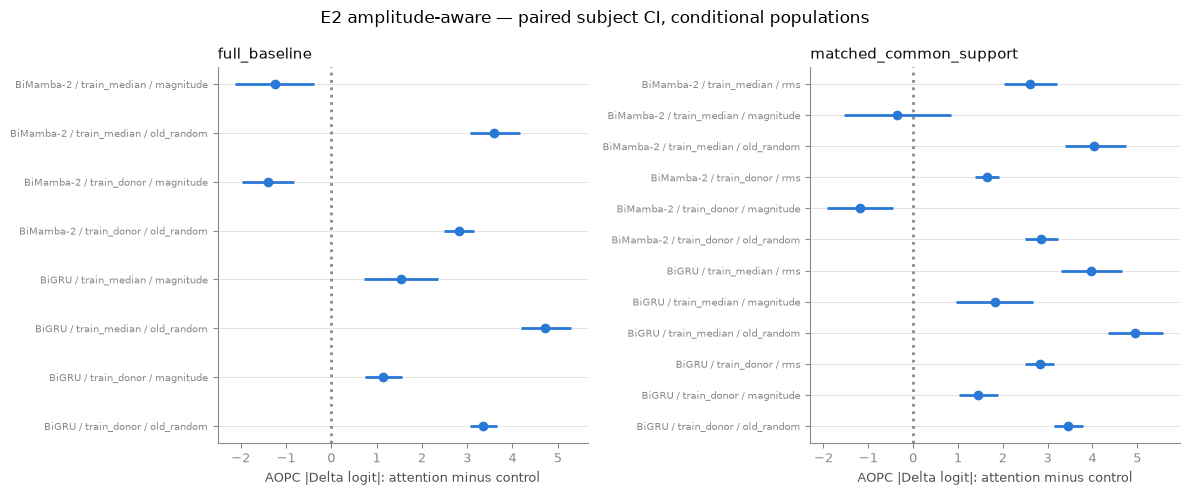

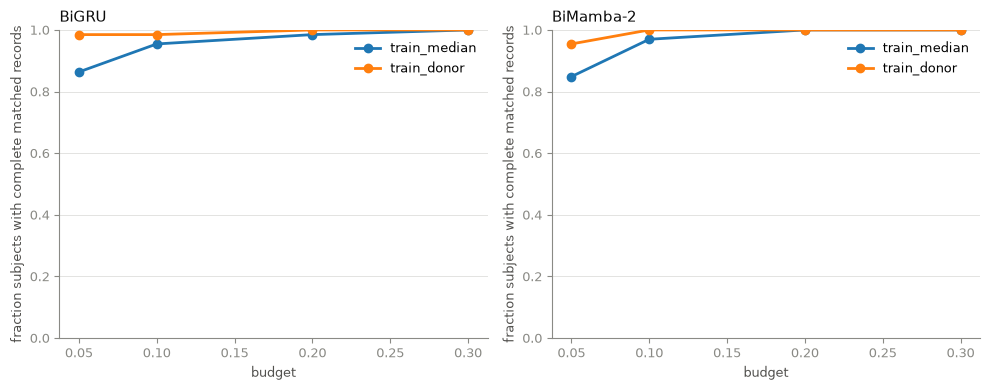

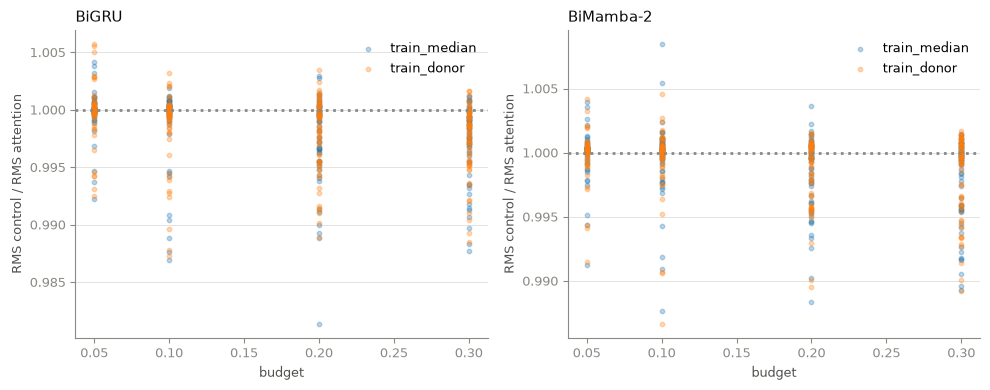

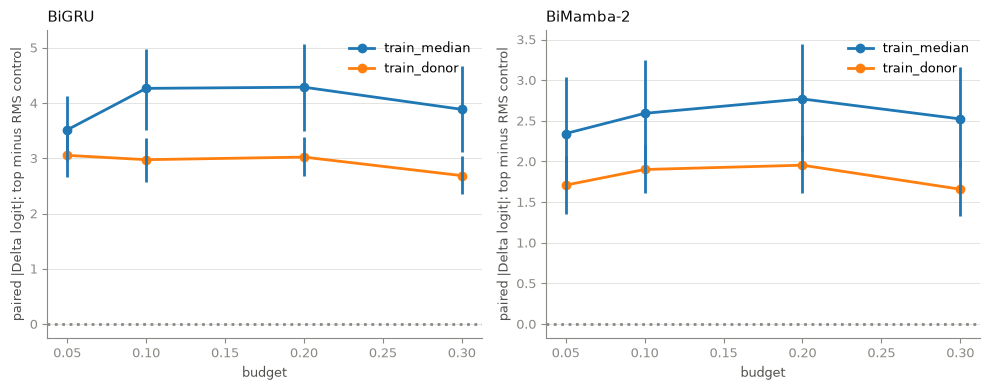

In [12]:
def savefig(fig,name):
    fig.savefig(FIG/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')

labels={'gru':'BiGRU','mamba2':'BiMamba-2'}
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,scope in zip(axes,('full_baseline','matched_common_support')):
    data=ci[(ci.scope==scope)&ci.metric.isin(['paired_old_random_abs_delta_logit',
                    'paired_magnitude_abs_delta_logit','paired_rms_abs_delta_logit'])].reset_index(drop=True)
    names=[]
    for i,row in enumerate(data.itertuples()):
        names.append(labels[row.architecture]+' / '+row.masker+' / '+row.metric.removeprefix('paired_').removesuffix('_abs_delta_logit'))
        if np.isfinite(row.estimate):
            ax.plot(row.estimate,i,'o',color='#2a78d6')
        if np.isfinite(row.ci_low) and np.isfinite(row.ci_high):
            ax.hlines(i,row.ci_low,row.ci_high,color='#2a78d6')
    ax.set_yticks(range(len(names)),names,fontsize=7)
    ax.axvline(0,color='#8a8a85',ls=':');ax.set_xlabel('AOPC |Delta logit|: attention minus control')
    ax.set_title(scope,loc='left');rapikan(ax)
fig.suptitle('E2 amplitude-aware — paired subject CI, conditional populations')
fig.tight_layout();savefig(fig,'paired_contrasts');plt.show()

fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,arm in zip(axes,ARMS):
    data=budget_coverage[(budget_coverage.scope=='matched_common_support')&(budget_coverage.architecture==arm)]
    for masker in ('train_median','train_donor'):
        d=data[data.masker==masker].sort_values('requested_fraction')
        ax.plot(d.requested_fraction,d.n_subjects_eligible/d.n_subjects_total,'o-',label=masker)
    ax.set_ylim(0,1);ax.set_xlabel('budget');ax.set_ylabel('fraction subjects with complete matched records')
    ax.set_title(labels[arm],loc='left');ax.legend();rapikan(ax)
fig.tight_layout();savefig(fig,'matching_coverage');plt.show()

fig,axes=plt.subplots(1,2,figsize=(10,4))
matched=balance[balance.control=='rms_matched_random'].copy()
matched['rms_ratio']=np.divide(matched.input_rms_change,matched.target_rms,
    out=np.full(len(matched),np.nan),where=matched.target_rms.to_numpy()>RMS_ABS_TOL)
for ax,arm in zip(axes,ARMS):
    for masker in ('train_median','train_donor'):
        d=matched[(matched.architecture==arm)&(matched.masker==masker)]
        ax.scatter(d.requested_fraction,d.rms_ratio,s=10,alpha=.3,label=masker)
    ax.axhline(1,color='#8a8a85',ls=':');ax.set_xlabel('budget');ax.set_ylabel('RMS control / RMS attention')
    ax.set_title(labels[arm],loc='left');ax.legend();rapikan(ax)
fig.tight_layout();savefig(fig,'rms_balance');plt.show()

fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,arm in zip(axes,ARMS):
    d=budget_ci[(budget_ci.architecture==arm)&(budget_ci.scope=='matched_common_support')&
                (budget_ci.metric=='paired_rms_abs_delta_logit')]
    for masker in ('train_median','train_donor'):
        group=d[d.masker==masker].sort_values('requested_fraction')
        ax.plot(group.requested_fraction,group.estimate,'o-',label=masker)
        valid=group[np.isfinite(group.ci_low)&np.isfinite(group.ci_high)]
        ax.vlines(valid.requested_fraction,valid.ci_low,valid.ci_high)
    ax.axhline(0,color='#8a8a85',ls=':');ax.set_xlabel('budget');ax.set_ylabel('paired |Delta logit|: top minus RMS control')
    ax.set_title(labels[arm],loc='left');ax.legend();rapikan(ax)
fig.tight_layout();savefig(fig,'budget_matched_contrasts');plt.show()


## 9. Penyelesaian, keluaran dan kriteria interpretasi

| Keluaran | Yang diperiksa |
|---|---|
| `analysis_manifest.json`, `input_inventory.csv`, `model_inventory.csv` | exploratory, checkpoint-only, sumber/data/spec tetap, run lengkap |
| `backend_native_warmup.csv`, `backend_native_profile.json` | dua forward asli untuk memperoleh pilihan autotuner yang benar-benar berjalan; bukan hasil E1/E2 |
| `backend_recovery.csv`, `backend_replay_points.csv` | profil ditolak resource dibedakan dari mismatch numerik; tidak diinterpretasi sebagai hasil penelitian |
| `cache_runtime_checks.csv`, `results/e2_amplitude_backend_profiles/*.json` | replay kontrol cache Mamba, profil kernel tersimpan/dikunci dan hash source runtime |
| `alpha_alignment_diagnostics.csv`, `alpha_details/*.npz` | nilai alpha vs mask pada semua budget; `strict_values` atau `exact_masks_all_point_replay`; jika gagal, identitas/selisih tersimpan |
| `baseline_replay_checks.csv`, `controls_raw.csv` | original/attention anchor, mask indices/hash, RMS, geometri, overlap, repeat dan output |
| `matching_diagnostics.csv`, `matching_search_summary.csv` | target yang gagal, kuota donor, batas pencarian, nearest sebagai diagnostik saja, RMS nol |
| `coverage.csv`, `budget_coverage.csv` | subjek/rekaman eligible; perbedaan populasi penuh dan matched |
| `point_contrasts.csv`, `record_contrasts.csv` | kontras pasangan pada checkpoint/rekaman/budget sama; NaN untuk matching tidak lengkap |
| `subject_contrasts.csv`, `paired_ci.csv` | area kurva, mean seed/rekaman/subjek, CI conditional dan flag cakupan rendah |
| `budget_subject_contrasts.csv`, `budget_paired_ci.csv` | empat budget terpisah, tidak mengisi budget yang gagal |
| `record_population.csv`, `budget_record_population.csv`, `balance_by_subject.csv` | audit denominator/subset dan keseimbangan RMS/geometri |
| `paired_contrasts`, `matching_coverage`, `rms_balance`, `budget_matched_contrasts` | PNG/PDF: kontras, cakupan, balance dan sensitivitas budget |

1. Verifikasi run `complete`, anchor/replay, kuota, mismatch RMS dan cakupan dahulu.
2. CI top−magnitude dan top−RMS yang positif mendukung kegunaan ranking attention
   melampaui **kontrol yang diuji**, pada populasi eligible tersebut. Magnitude
   comparator tetap mempunyai geometri berbeda. Matching global RMS bukan bukti
   independensi dari seluruh karakteristik amplitudo/spektral input.
3. CI mencakup nol berarti belum menentukan; bukan bukti ekuivalensi atau bahwa
   attention tidak faithful. Kontras negatif menunjukkan kontrol lebih kuat pada
   pengujian itu; bukan bukti kegagalan klinis atau kausalitas fisiologis.
4. Jika matching jarang, berbeda menurut arsitektur/kelas, overlap mask sangat
   tinggi, atau CI disembunyikan akibat cakupan rendah, batasi kesimpulan. Jangan
   melakukan fallback, mengganti kaliper, atau memilih budget berdasarkan arah CI.
5. Kontras ini membandingkan respons tiap checkpoint dengan kontrolnya, bukan
   keunggulan arsitektur antar-populasi matching yang berbeda. E1/E2 lama tetap
   baseline dan status preregistrasi tidak berubah. E3 belum dilakukan.


In [13]:
runtime_objects,_,_=runtime_kernels()
for name,obj in runtime_objects.items():
    if len(obj.configs)!=1 or config_payload(obj.configs[0])!=runtime_profile['spec']['kernels'][name]:
        raise AlignmentError('profil runtime berubah selama run: '+name)
if (torch.get_float32_matmul_precision()!=manifest['backend_context']['float32_matmul_precision']
        or bool(torch.backends.cuda.matmul.allow_tf32)!=manifest['backend_context']['cuda_matmul_allow_tf32']
        or bool(torch.backends.cudnn.allow_tf32)!=manifest['backend_context']['cudnn_allow_tf32']):
    raise AlignmentError('precision context berubah selama run')
inventory['sha256_after']=[file_sha256(ROOT/p) for p in inventory.path]
inventory['unchanged']=inventory.sha256_before==inventory.sha256_after
inventory.to_csv(OUT/'input_inventory.csv',index=False)
source_unchanged=notebook_source_digest(NOTEBOOK_PATH)==SOURCE_DIGEST
manifest['notebook_source_unchanged']=source_unchanged
if not inventory.unchanged.all() or not source_unchanged:
    manifest['completion_status']='invalid_inputs_changed'
    (OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    raise AlignmentError('input/baseline/checkpoint/sumber berubah selama run; hasil tidak digunakan')
manifest.update(completion_status='complete',completed_utc=datetime.now(timezone.utc).isoformat(),
    n_models=len(model_inventory),training_performed=False,
    n_models_reused_legacy_cache=int(model_inventory.reused_legacy_cache.sum()),
    alpha_validation_counts=pd.DataFrame(diagnostic_rows).verification.value_counts().to_dict(),
    tables=sorted(p.name for p in OUT.glob('*.csv')),figures=sorted(p.name for p in FIG.iterdir()),
    matching_limit='bounded input-only rejection sampling; incomplete targets not imputed or reweighted',
    claim_status='exploratory; no automatic faithfulness claim')
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Selesai:',OUT)
print('Checkpoint dipakai ulang; tidak ada training. E1/E2 sebelumnya tidak berubah.')
print('Kontrol amplitude-aware tetap exploratory; baca coverage/balance sebelum menafsirkan CI.')


Selesai: /home/agribychaniago/Python Projects/Skripsi/results/e2_amplitude/20261014T024232464643Z
Checkpoint dipakai ulang; tidak ada training. E1/E2 sebelumnya tidak berubah.
Kontrol amplitude-aware tetap exploratory; baca coverage/balance sebelum menafsirkan CI.
